## 1. Imports & config

In [1]:
import os
import pickle
from itertools import product

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

import astropy.table as at
import astropy.units as u
import astropy.coordinates as coord
from astropy.table import Table
from astropy.coordinates import SkyCoord, Distance
from matplotlib.path import Path

import jax
import jax.numpy as jnp
import jax.random as jr

import arviz as az
import numpyro
import numpyro.distributions as dist
import numpyro.infer as infer

from scipy.stats import binned_statistic
from scipy.optimize import brentq
from tqdm import tqdm

jax.config.update("jax_enable_x64", True)
%matplotlib inline

## 2. Load tables & selection cuts → `t_final`

Loads the FITS tables, applies the pre-chem selection, the low-α + [Fe/H] cut, and
the [Al/Fe]-[Mg/Mn] polygon cut. Ends with `t_final`.

In [2]:
t2 = Table.read("astraAllStarAstroNNdist-0.8.0-bugfix20260709.fits", format="fits", hdu=2)
t2.colnames

['sdss_id',
 'sdss4_apogee_id',
 'gaia_dr2_source_id',
 'gaia_dr3_source_id',
 'tic_v8_id',
 'healpix',
 'lead',
 'version_id',
 'catalogid',
 'catalogid21',
 'catalogid25',
 'catalogid31',
 'n_associated',
 'n_neighborhood',
 'crossmatch_flags',
 'sdss5_target_flags',
 'sdss4_apogee_target1_flags',
 'sdss4_apogee_target2_flags',
 'sdss4_apogee2_target1_flags',
 'sdss4_apogee2_target2_flags',
 'sdss4_apogee2_target3_flags',
 'sdss4_apogee_member_flags',
 'sdss4_apogee_extra_target_flags',
 'ra',
 'dec',
 'l',
 'b',
 'plx',
 'e_plx',
 'pmra',
 'e_pmra',
 'pmde',
 'e_pmde',
 'gaia_v_rad',
 'gaia_e_v_rad',
 'g_mag',
 'bp_mag',
 'rp_mag',
 'j_mag',
 'e_j_mag',
 'h_mag',
 'e_h_mag',
 'k_mag',
 'e_k_mag',
 'ph_qual',
 'bl_flg',
 'cc_flg',
 'w1_mag',
 'e_w1_mag',
 'w1_flux',
 'w1_dflux',
 'w1_frac',
 'w2_mag',
 'e_w2_mag',
 'w2_flux',
 'w2_dflux',
 'w2_frac',
 'w1uflags',
 'w2uflags',
 'w1aflags',
 'w2aflags',
 'mag4_5',
 'd4_5m',
 'rms_f4_5',
 'sqf_4_5',
 'mf4_5',
 'csf',
 'zgr_teff',
 'zgr_

In [3]:
t2_sdss_id = np.asarray(t2["sdss_id"])
dist_col = np.asarray(t2["dist_bugfix"], float)
print("dist_bugfix shape:", dist_col.shape)  # check for the (N,1) quirk like AgeJTsketchy had
if dist_col.ndim > 1:
    dist_col = dist_col.ravel()

# any crossmatch at all
has_any_t2_match = np.isin(final_sdss_id, t2_sdss_id)

# valid: finite, not the -1 fill sentinel, and within a sane physical range (<50 kpc in pc)
valid_dist_mask = (
    np.isfinite(dist_col)
    & (dist_col > 0) & (dist_col < 50_000)
    & (t2_sdss_id != -1)
)
t2_sdss_id_valid = t2_sdss_id[valid_dist_mask]
has_valid_dist = np.isin(final_sdss_id, t2_sdss_id_valid)

print(f"t_final stars with ANY t2 match: {has_any_t2_match.sum()} / {len(t_final)} "
      f"({100 * has_any_t2_match.sum() / len(t_final):.1f}%)")

print(f"t_final stars with a valid dist_bugfix: {has_valid_dist.sum()} / {len(t_final)} "
      f"({100 * has_valid_dist.sum() / len(t_final):.1f}%)")

matched_but_check = has_any_t2_match.sum()
if matched_but_check > 0:
    print(f"of t_final stars with a t2 match, fraction with valid dist_bugfix: "
          f"{100 * has_valid_dist.sum() / matched_but_check:.1f}%")

print("t2 sdss_id == -1 count:", np.sum(t2_sdss_id == -1))
print("t2 sdss_id == 0 count:", np.sum(t2_sdss_id == 0))

dist_bugfix shape: (2408246,)


NameError: name 'final_sdss_id' is not defined

In [33]:
n_total_t2 = len(t2_sdss_id)
n_not_finite = np.sum(~np.isfinite(dist_col))
n_nonpositive = np.sum(np.isfinite(dist_col) & (dist_col <= 0))
n_too_far = np.sum(np.isfinite(dist_col) & (dist_col >= 50_000))

print(f"t2 rows total: {n_total_t2}")
print(f"  not finite (NaN/inf): {n_not_finite} ({100*n_not_finite/n_total_t2:.1f}%)")
print(f"  finite but <= 0: {n_nonpositive} ({100*n_nonpositive/n_total_t2:.1f}%)")
print(f"  finite but >= 50 kpc: {n_too_far} ({100*n_too_far/n_total_t2:.1f}%)")

t2 rows total: 2408246
  not finite (NaN/inf): 1179048 (49.0%)
  finite but <= 0: 0 (0.0%)
  finite but >= 50 kpc: 16509 (0.7%)


In [25]:
t3 = Table.read("StarFlow_summary_v1_0_0.fits", format="fits", hdu=1)
t3["sdss4_apogee_id"] = t3["sdss4_apogee_id"].filled(-1)

dr17 = Table.read("allStarLite-dr17-synspec_rev1.fits", hdu=1)
t3 = at.join(
    t3,
    dr17["APOGEE_ID", "SNR", "VHELIO_AVG"],
    keys_left="sdss4_apogee_id",
    keys_right="APOGEE_ID",
    join_type="left",
)
print("loaded StarFlow_summary_v1_0_0:", len(t3))
t3.colnames

loaded StarFlow_summary_v1_0_0: 1287381


['sdss_id',
 'sdss4_apogee_id',
 'age',
 'e_p_age',
 'e_n_age',
 'mass',
 'e_p_mass',
 'e_n_mass',
 'training_density',
 'BITMASK',
 'APOGEE_ID',
 'SNR',
 'VHELIO_AVG']

In [26]:
t3_sdss_id = np.asarray(t3["sdss_id"])
age_col = np.asarray(t3["age"], float)
if age_col.ndim > 1:
    age_col = age_col.ravel()

# any crossmatch at all, ignoring whether age is valid
has_any_t3_match = np.isin(final_sdss_id, t3_sdss_id)

# valid: finite age, not the -1 fill sentinel
valid_age_mask = np.isfinite(age_col) & (t3_sdss_id != -1)
t3_sdss_id_valid = t3_sdss_id[valid_age_mask]
has_valid_age = np.isin(final_sdss_id, t3_sdss_id_valid)

print(f"RGB stars with ANY StarFlow_summary_v1_0_0 match: {has_any_t3_match.sum()} / {len(t_final)} "
      f"({100 * has_any_t3_match.sum() / len(t_final):.1f}%)")

print(f"RGB stars with a valid age: {has_valid_age.sum()} / {len(t_final)} "
      f"({100 * has_valid_age.sum() / len(t_final):.1f}%)")

matched_but_check = has_any_t3_match.sum()
if matched_but_check > 0:
    print(f"of RGB stars with a StarFlow_summary_v1_0_0 match, fraction with valid age: "
          f"{100 * has_valid_age.sum() / matched_but_check:.1f}%")

print("t3 sdss_id == -1 count:", np.sum(t3_sdss_id == -1))

RGB stars with ANY StarFlow_summary_v1_0_0 match: 213804 / 391384 (54.6%)
RGB stars with a valid age: 210837 / 391384 (53.9%)
of RGB stars with a StarFlow_summary_v1_0_0 match, fraction with valid age: 98.6%
t3 sdss_id == -1 count: 8


In [50]:
t4 = Table.read("IPL42_agesJT.fits", format="fits")
print(t4.colnames)
print("n rows:", len(t4))

['sdss_id', 'AgeJTsketchy']
n rows: 921442


In [51]:
print("t_final" , "has sdss_id:", "sdss_id" in t_final.colnames)
if "sdss_id" in t_final.colnames:
    print("t_final sdss_id dtype:", t_final["sdss_id"].dtype)
    print("example t_final sdss_id:", repr(t_final["sdss_id"][0]))

print("t4 sdss_id dtype:", t4["sdss_id"].dtype)
print("example t4 sdss_id:", repr(t4["sdss_id"][0]))

t_final has sdss_id: True
t_final sdss_id dtype: >i8
example t_final sdss_id: np.int64(84326244)
t4 sdss_id dtype: >i8
example t4 sdss_id: np.int64(69834792)


In [52]:
age_col_t4 = np.asarray(t4["AgeJTsketchy"], float).ravel()  # (921442, 1) -> (921442,)
print("age_col_t4 shape:", age_col_t4.shape)

t4_sdss_id = np.asarray(t4["sdss_id"])

# any crossmatch at all
has_any_t4_match = np.isin(final_sdss_id, t4_sdss_id)

# valid: finite age
valid_age_mask_t4 = np.isfinite(age_col_t4)
t4_sdss_id_valid = t4_sdss_id[valid_age_mask_t4]
has_valid_age_t4 = np.isin(final_sdss_id, t4_sdss_id_valid)

print(f"t_final stars with ANY t4 match: {has_any_t4_match.sum()} / {len(t_final)} "
      f"({100 * has_any_t4_match.sum() / len(t_final):.1f}%)")

print(f"t_final stars with a valid age (t4): {has_valid_age_t4.sum()} / {len(t_final)} "
      f"({100 * has_valid_age_t4.sum() / len(t_final):.1f}%)")

matched_but_check_t4 = has_any_t4_match.sum()
if matched_but_check_t4 > 0:
    print(f"of t_final stars with a t4 match, fraction with valid age: "
          f"{100 * has_valid_age_t4.sum() / matched_but_check_t4:.1f}%")

print("t4 sdss_id == 0 count:", np.sum(t4_sdss_id == 0))
print("t_final sdss_id == 0 count:", np.sum(final_sdss_id == 0))

age_col_t4 shape: (921442,)
t_final stars with ANY t4 match: 352439 / 391384 (90.0%)
t_final stars with a valid age (t4): 352439 / 391384 (90.0%)
of t_final stars with a t4 match, fraction with valid age: 100.0%
t4 sdss_id == 0 count: 0
t_final sdss_id == 0 count: 0


In [53]:
age_col_t4 = np.asarray(t4["AgeJTsketchy"], float).ravel()

n_total = len(age_col_t4)
n_nan = np.sum(np.isnan(age_col_t4))
n_inf = np.sum(np.isinf(age_col_t4))
n_finite = np.sum(np.isfinite(age_col_t4))

print(f"total: {n_total}")
print(f"finite: {n_finite} ({100*n_finite/n_total:.1f}%)")
print(f"NaN: {n_nan} ({100*n_nan/n_total:.1f}%)")
print(f"inf: {n_inf} ({100*n_inf/n_total:.1f}%)")
print(f"finite + NaN + inf accounted for: {n_finite + n_nan + n_inf} / {n_total}")

# check for suspicious sentinel-looking values among the finite ones
finite_ages = age_col_t4[np.isfinite(age_col_t4)]
print("\nmin finite age:", finite_ages.min())
print("max finite age:", finite_ages.max())
print("negative finite ages:", np.sum(finite_ages < 0))
print("zero ages:", np.sum(finite_ages == 0))

# common sentinel values to check for specifically
for sentinel in [-999, -99, -9999, 999, 0]:
    count = np.sum(age_col_t4 == sentinel)
    if count > 0:
        print(f"age == {sentinel}: {count} rows")

total: 921442
finite: 921442 (100.0%)
NaN: 0 (0.0%)
inf: 0 (0.0%)
finite + NaN + inf accounted for: 921442 / 921442

min finite age: -5.842303105919575
max finite age: 41.86288879006953
negative finite ages: 768
zero ages: 0


In [54]:
finite_ages = age_col_t4[np.isfinite(age_col_t4)]

n_above_14 = np.sum(finite_ages > 14)
print(f"ages > 14 Gyr: {n_above_14} / {len(finite_ages)} ({100*n_above_14/len(finite_ages):.2f}%)")

above_14 = finite_ages[finite_ages > 14]
if len(above_14) > 0:
    print("min:", above_14.min())
    print("max:", above_14.max())
    print("median:", np.median(above_14))

n_above_20 = np.sum(finite_ages > 20)
print(f"\nages > 20 Gyr: {n_above_20}")

ages > 14 Gyr: 1425 / 921442 (0.15%)
min: 14.000057586988548
max: 41.86288879006953
median: 16.233581946440893

ages > 20 Gyr: 297


In [55]:
age_col_t4 = np.asarray(t4["AgeJTsketchy"], float).ravel()

# valid: finite, and within a sane physical range (0-15 Gyr)
valid_age_mask_t4 = np.isfinite(age_col_t4) & (age_col_t4 >= 0) & (age_col_t4 <= 15)

t4_sdss_id_valid = t4_sdss_id[valid_age_mask_t4]
has_valid_age_t4 = np.isin(final_sdss_id, t4_sdss_id_valid)

print(f"t_final stars with ANY t4 match: {has_any_t4_match.sum()} / {len(t_final)} "
      f"({100 * has_any_t4_match.sum() / len(t_final):.1f}%)")

print(f"t_final stars with a valid age (0-15 Gyr): {has_valid_age_t4.sum()} / {len(t_final)} "
      f"({100 * has_valid_age_t4.sum() / len(t_final):.1f}%)")

matched_but_check_t4 = has_any_t4_match.sum()
if matched_but_check_t4 > 0:
    print(f"of t_final stars with a t4 match, fraction with valid age: "
          f"{100 * has_valid_age_t4.sum() / matched_but_check_t4:.1f}%")

t_final stars with ANY t4 match: 352439 / 391384 (90.0%)
t_final stars with a valid age (0-15 Gyr): 352398 / 391384 (90.0%)
of t_final stars with a t4 match, fraction with valid age: 100.0%


In [2]:
t = Table.read("astraAllStarASPCAP-0.8.fits.gz", format="fits", hdu=2)
t["sdss4_apogee_id"] = t["sdss4_apogee_id"].filled(-1)

dr17 = Table.read("allStarLite-dr17-synspec_rev1.fits", hdu=1)
t = at.join(
    t,
    dr17["APOGEE_ID", "SNR", "VHELIO_AVG"],
    keys_left="sdss4_apogee_id",
    keys_right="APOGEE_ID",
    join_type="left",
)
print("loaded t:", len(t))

loaded t: 2576187


In [3]:
from src.selection import build_prechem_selection

master_mask, sel_diag, sel_arrays = build_prechem_selection(t)
t_sel = t[master_mask]
print("pre-chem selected:", sel_diag["prechem_selected"])

pre-chem selected: 630079


In [4]:
from src.coords import build_galactocentric_xyz
from src.chemistry import apply_low_alpha_cut, FEH_CUT
from src.utils import col_to_float_array
from src.chemistry import apply_high_alpha_cut, FE_BREAK, M1, B1, M2, B2

x, y, z = build_galactocentric_xyz(t_sel)
chem_result = apply_high_alpha_cut(t_sel, x=x, y=y, z=z)

t_sel = chem_result["table"]
fe   = chem_result["fe"]
mgfe = chem_result["mgfe"]
print(f"after high-α :", len(t_sel))

after high-α : 153396


In [6]:
t_final = t_sel
print("t_final size:", len(t_final))

t_final size: 153396


## 3. Galactocentric phase space & `star_pack`

In [7]:
from src.coords import build_galactocentric_phase_space

phase, phase_diag = build_galactocentric_phase_space(t_final)

X    = phase["X"]
Y    = phase["Y"]
Z    = phase["Z"]
R    = phase["R"]
vphi = phase["vphi"]
vz   = phase["vz"]
print("N stars in phase-space sample:", phase_diag["phase_space_size"])

N stars in phase-space sample: 134696


In [8]:
from src.utils import col_to_float_array
from src.coords import build_star_pack, build_segment_setup

star_pack, star_diag = build_star_pack(
    t_final,
    rmax_keep=16,
    plx_min=None
)

R_star    = star_pack["R_star"]
Z_star    = star_pack["Z_star"]
phi_star  = star_pack["phi_star"]
mgfe_star = star_pack["mgfe_star"]
t_star    = star_pack["t_star"]

segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(
    phi_star,
    phi0=np.pi,
    crowd_halfwidth_deg=45,
    n_crowd=11
)

SEG_PLOT      = list(range(1, seg_diag["n_crowd"] + 2))   # crowded segments + rest
SEG_PLOT_heat = list(range(1, seg_diag["n_crowd"] + 1))   # crowded segments only

e_mg_h_star = col_to_float_array(t_star, "e_mg_h")
e_fe_h_star = col_to_float_array(t_star, "e_fe_h")

assert len(R_star) == len(Z_star) == len(phi_star) == len(mgfe_star)
assert len(R_star) == len(e_mg_h_star) == len(e_fe_h_star)
assert len(R_star) == len(segm[1])

print("star_pack final size:", star_diag["final_size"])

star_pack final size: 153349


In [9]:
print(f"final sample: {len(t_star)} stars")

final sample: 153349 stars


In [10]:
# per-star [Mg/Fe] error proxy: sigma([Mg/Fe]) = sqrt(sigma([Mg/H])^2 + sigma([Fe/H])^2)
mgfe_err_star = np.sqrt(np.asarray(e_mg_h_star, float)**2 + np.asarray(e_fe_h_star, float)**2)

finite_all = (
    np.isfinite(R_star) & np.isfinite(Z_star) & np.isfinite(phi_star) &
    np.isfinite(mgfe_star) & np.isfinite(mgfe_err_star) & (mgfe_err_star > 0)
)
print("stars with finite (R, Z, phi, mgfe, mgfe_err):", int(finite_all.sum()), "/", len(R_star))

stars with finite (R, Z, phi, mgfe, mgfe_err): 152610 / 153349


In [11]:
print(f"radial bins: {R_edges}")
print(f"R range: {R_edges[0]:.1f} - {R_edges[-1]:.1f} kpc, {len(R_edges)-1} bins, {R_edges[1]-R_edges[0]:.1f} kpc wide")

NameError: name 'R_edges' is not defined

In [12]:
theta_edges_deg_emma = np.degrees(np.unwrap(np.array(crowd_bounds, float)))
for i in range(1, len(theta_edges_deg_emma)):
    while theta_edges_deg_emma[i] <= theta_edges_deg_emma[i-1]:
        theta_edges_deg_emma[i] += 360

print(f"azimuthal bin edges (your convention, Sun at 180°): {theta_edges_deg_emma}")
print(f"azimuthal range: {theta_edges_deg_emma[0]:.1f} - {theta_edges_deg_emma[-1]:.1f} deg, {len(theta_edges_deg_emma)-1} segments")

theta_edges_deg_poggio = 180.0 - theta_edges_deg_emma
theta_edges_deg_poggio = (theta_edges_deg_poggio + 180) % 360 - 180
print(f"azimuthal bin edges (Poggio convention, phi=0 at anti-center): {sorted(theta_edges_deg_poggio)}")

azimuthal bin edges (your convention, Sun at 180°): [135.         143.18181818 151.36363636 159.54545455 167.72727273
 175.90909091 184.09090909 192.27272727 200.45454545 208.63636364
 216.81818182 225.        ]
azimuthal range: 135.0 - 225.0 deg, 11 segments
azimuthal bin edges (Poggio convention, phi=0 at anti-center): [np.float64(-45.0), np.float64(-36.81818181818181), np.float64(-28.636363636363654), np.float64(-20.454545454545467), np.float64(-12.272727272727252), np.float64(-4.0909090909090935), np.float64(4.0909090909090935), np.float64(12.27272727272728), np.float64(20.454545454545467), np.float64(28.636363636363654), np.float64(36.81818181818181), np.float64(45.0)]


NameError: name 'feh_min_extra' is not defined

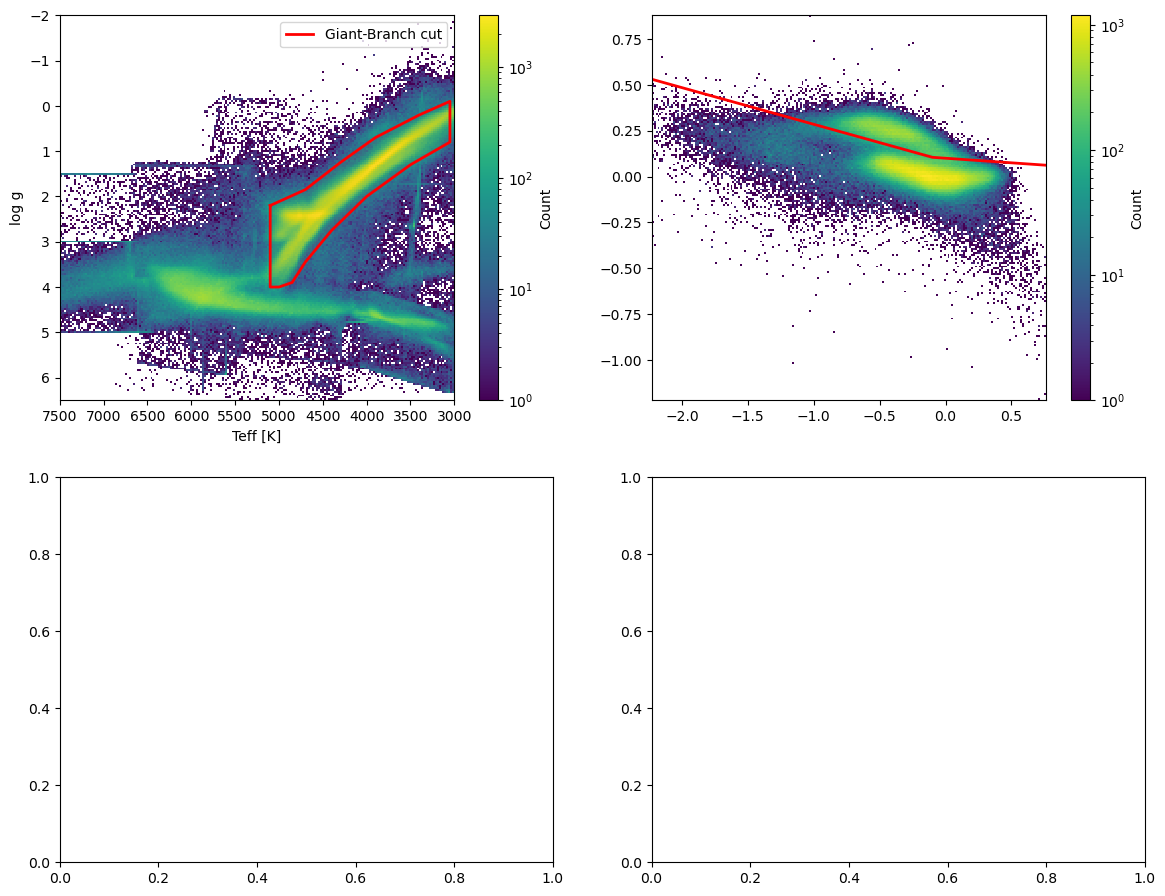

In [13]:
from src.utils import col_to_float_array
t_sel_gb = t[master_mask]
# [Fe/H] and [Mg/Fe] for the giant-branch-only sample (before the low-alpha + metallicity cuts)
fe_gb = col_to_float_array(t_sel_gb, "fe_h")
mgh_gb = col_to_float_array(t_sel_gb, "mg_h")
mgfe_gb = mgh_gb - fe_gb

import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm
from src.config import GB_VERTICES
from src.chemistry import mgfe_dividing_line, FEH_CUT

# pre-chemistry arrays for panel 2
fe_prechem = np.asarray(sel_arrays["feh"], float)
mgfe_prechem = np.asarray(sel_arrays["mgh"], float) - fe_prechem
finite_prechem = np.isfinite(fe_prechem) & np.isfinite(mgfe_prechem)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# ============================================================
# PANEL 1 (top left): Kiel diagram
# ============================================================
ax = axes[0, 0]
finite_basic = np.isfinite(sel_arrays["teff"]) & np.isfinite(sel_arrays["logg"])
x_all = np.asarray(sel_arrays["teff"], float)[finite_basic]
y_all = np.asarray(sel_arrays["logg"], float)[finite_basic]

h1 = ax.hist2d(
    x_all, y_all,
    bins=200,
    range=[(3000, 7500), (-2, 6.5)],
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h1[3], ax=ax, label="Count")

gb_closed = np.vstack([GB_VERTICES, GB_VERTICES[0]])
ax.plot(gb_closed[:, 0], gb_closed[:, 1], "r-", lw=2, label="Giant-Branch cut")
ax.fill(gb_closed[:, 0], gb_closed[:, 1], color="red", alpha=0.06)

ax.invert_xaxis()
ax.invert_yaxis()
ax.set_xlim(7500, 3000)
ax.set_ylim(6.5, -2)
ax.set_xlabel("Teff [K]")
ax.set_ylabel("log g")
ax.legend(loc="upper right")

# ============================================================
# PANEL 2 (top right): [Mg/Fe] vs [Fe/H] -- all giant branch stars
# ============================================================
ax = axes[0, 1]
h2 = ax.hist2d(
    fe_gb, mgfe_gb,
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h2[3], ax=ax, label="Count")

fe_grid = np.linspace(np.nanmin(fe_gb), np.nanmax(fe_gb), 400)
ax.plot(fe_grid, mgfe_dividing_line(fe_grid), color="red", lw=2, label="alpha-division")
ax.axvline(feh_min_extra, color="red", lw=2, ls="--", label=f"[Fe/H] = {feh_min_extra}")
ax.set_xlabel("[Fe/H]")
ax.set_ylabel("[Mg/Fe]")
ax.legend(loc="upper right")
ax.set_xlim(-1.5, 0.75)
ax.set_ylim(-1.25, 1.0)

# ============================================================
# PANEL 3 (bottom left): [Al/Fe] vs [Mg/Mn]
# ============================================================
ax = axes[1, 1]
h3 = ax.hist2d(
    final_arrays["x_finite"],
    final_arrays["y_finite"],
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h3[3], ax=ax, label="Count")
poly = np.vstack([final_arrays["poly_vertices"], final_arrays["poly_vertices"][0]])
ax.plot(poly[:, 0], poly[:, 1], "r-", lw=2, label="Disk polygon")
ax.set_xlabel("[Al/Fe]")
ax.set_ylabel("[Mg/Mn]")
ax.legend(loc="upper right")
ax.set_xlim(-1.5, 1.25)
ax.set_ylim(-0.75, 1.25)

axes[1, 0].axis("off")

plt.tight_layout()
plt.show()

NameError: name 'feh_min_extra' is not defined

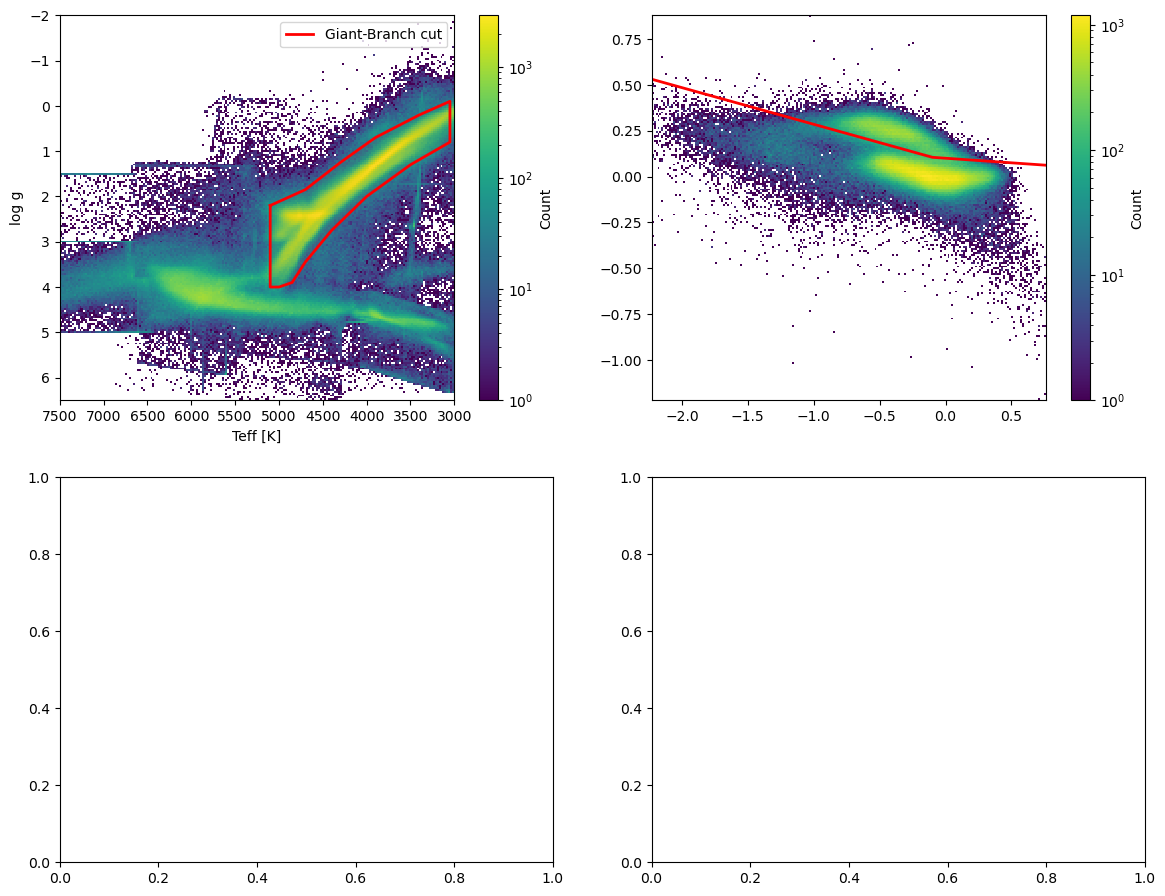

In [14]:
from src.utils import col_to_float_array
t_sel_gb = t[master_mask]
# [Fe/H] and [Mg/Fe] for the giant-branch-only sample (before the low-alpha + metallicity cuts)
fe_gb = col_to_float_array(t_sel_gb, "fe_h")
mgh_gb = col_to_float_array(t_sel_gb, "mg_h")
mgfe_gb = mgh_gb - fe_gb

import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm
from src.config import GB_VERTICES
from src.chemistry import mgfe_dividing_line, FEH_CUT

# pre-chemistry arrays for panel 2
fe_prechem = np.asarray(sel_arrays["feh"], float)
mgfe_prechem = np.asarray(sel_arrays["mgh"], float) - fe_prechem
finite_prechem = np.isfinite(fe_prechem) & np.isfinite(mgfe_prechem)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# ============================================================
# PANEL 1 (top left): Kiel diagram
# ============================================================
ax = axes[0, 0]
finite_basic = np.isfinite(sel_arrays["teff"]) & np.isfinite(sel_arrays["logg"])
x_all = np.asarray(sel_arrays["teff"], float)[finite_basic]
y_all = np.asarray(sel_arrays["logg"], float)[finite_basic]

h1 = ax.hist2d(
    x_all, y_all,
    bins=200,
    range=[(3000, 7500), (-2, 6.5)],
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h1[3], ax=ax, label="Count")

gb_closed = np.vstack([GB_VERTICES, GB_VERTICES[0]])
ax.plot(gb_closed[:, 0], gb_closed[:, 1], "r-", lw=2, label="Giant-Branch cut")
ax.fill(gb_closed[:, 0], gb_closed[:, 1], color="red", alpha=0.06)

ax.invert_xaxis()
ax.invert_yaxis()
ax.set_xlim(7500, 3000)
ax.set_ylim(6.5, -2)
ax.set_xlabel("Teff [K]")
ax.set_ylabel("log g")
ax.legend(loc="upper right")

# ============================================================
# PANEL 2 (top right): [Mg/Fe] vs [Fe/H] -- all giant branch stars
# ============================================================
ax = axes[0, 1]
h2 = ax.hist2d(
    fe_gb, mgfe_gb,
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h2[3], ax=ax, label="Count")

fe_grid = np.linspace(np.nanmin(fe_gb), np.nanmax(fe_gb), 400)
ax.plot(fe_grid, mgfe_dividing_line(fe_grid), color="red", lw=2, label="alpha-division")
ax.axvline(feh_min_extra, color="red", lw=2, ls="--", label=f"[Fe/H] = {feh_min_extra}")
ax.set_xlabel("[Fe/H]")
ax.set_ylabel("[Mg/Fe]")
ax.legend(loc="upper right")
ax.set_xlim(-1.5, 0.75)
ax.set_ylim(-1.25, 1.0)

# ============================================================
# PANEL 3 (bottom left): [Al/Fe] vs [Mg/Mn]
# ============================================================
ax = axes[1, 0]
h3 = ax.hist2d(
    final_arrays["x_finite"],
    final_arrays["y_finite"],
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h3[3], ax=ax, label="Count")

poly = np.vstack([final_arrays["poly_vertices"], final_arrays["poly_vertices"][0]])
ax.plot(poly[:, 0], poly[:, 1], "r-", lw=2, label="Disk polygon")
ax.set_xlabel("[Al/Fe]")
ax.set_ylabel("[Mg/Mn]")
ax.legend(loc="upper right")
ax.set_xlim(-1.5, 1.25)
ax.set_ylim(-0.75, 1.25)

# ============================================================
# PANEL 4 (bottom right): XY density with wedge overlay
# ============================================================
ax = axes[1, 1]
h0 = ax.hist2d(X, Y, bins=200, cmap="magma", norm=mcolors.LogNorm())
fig.colorbar(h0[3], ax=ax, label="Count")

# sun marker
ax.plot(-8.275, 0, marker="*", color="yellow", markersize=12,
        markeredgecolor="k", markeredgewidth=0.5, label="Sun", zorder=5)

# wedge outline
theta_min_wed = 2.35619449
theta_max_wed = 3.92699082
R_min = 0
R_max = 16.0
theta_arc = np.linspace(theta_min_wed, theta_max_wed, 200)
ax.plot(R_min * np.cos(theta_arc), R_min * np.sin(theta_arc), color="cyan", lw=4)
ax.plot(R_max * np.cos(theta_arc), R_max * np.sin(theta_arc), color="cyan", lw=4)
ax.plot([R_min * np.cos(theta_min_wed), R_max * np.cos(theta_min_wed)],
        [R_min * np.sin(theta_min_wed), R_max * np.sin(theta_min_wed)], color="cyan", lw=4)
ax.plot([R_min * np.cos(theta_max_wed), R_max * np.cos(theta_max_wed)],
        [R_min * np.sin(theta_max_wed), R_max * np.sin(theta_max_wed)], color="cyan", lw=4,
        label="Survey region")
ax.set_xlabel("X [kpc]")
ax.set_ylabel("Y [kpc]")
ax.set_xlim(-17, 0)
ax.set_ylim(-12, 12)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

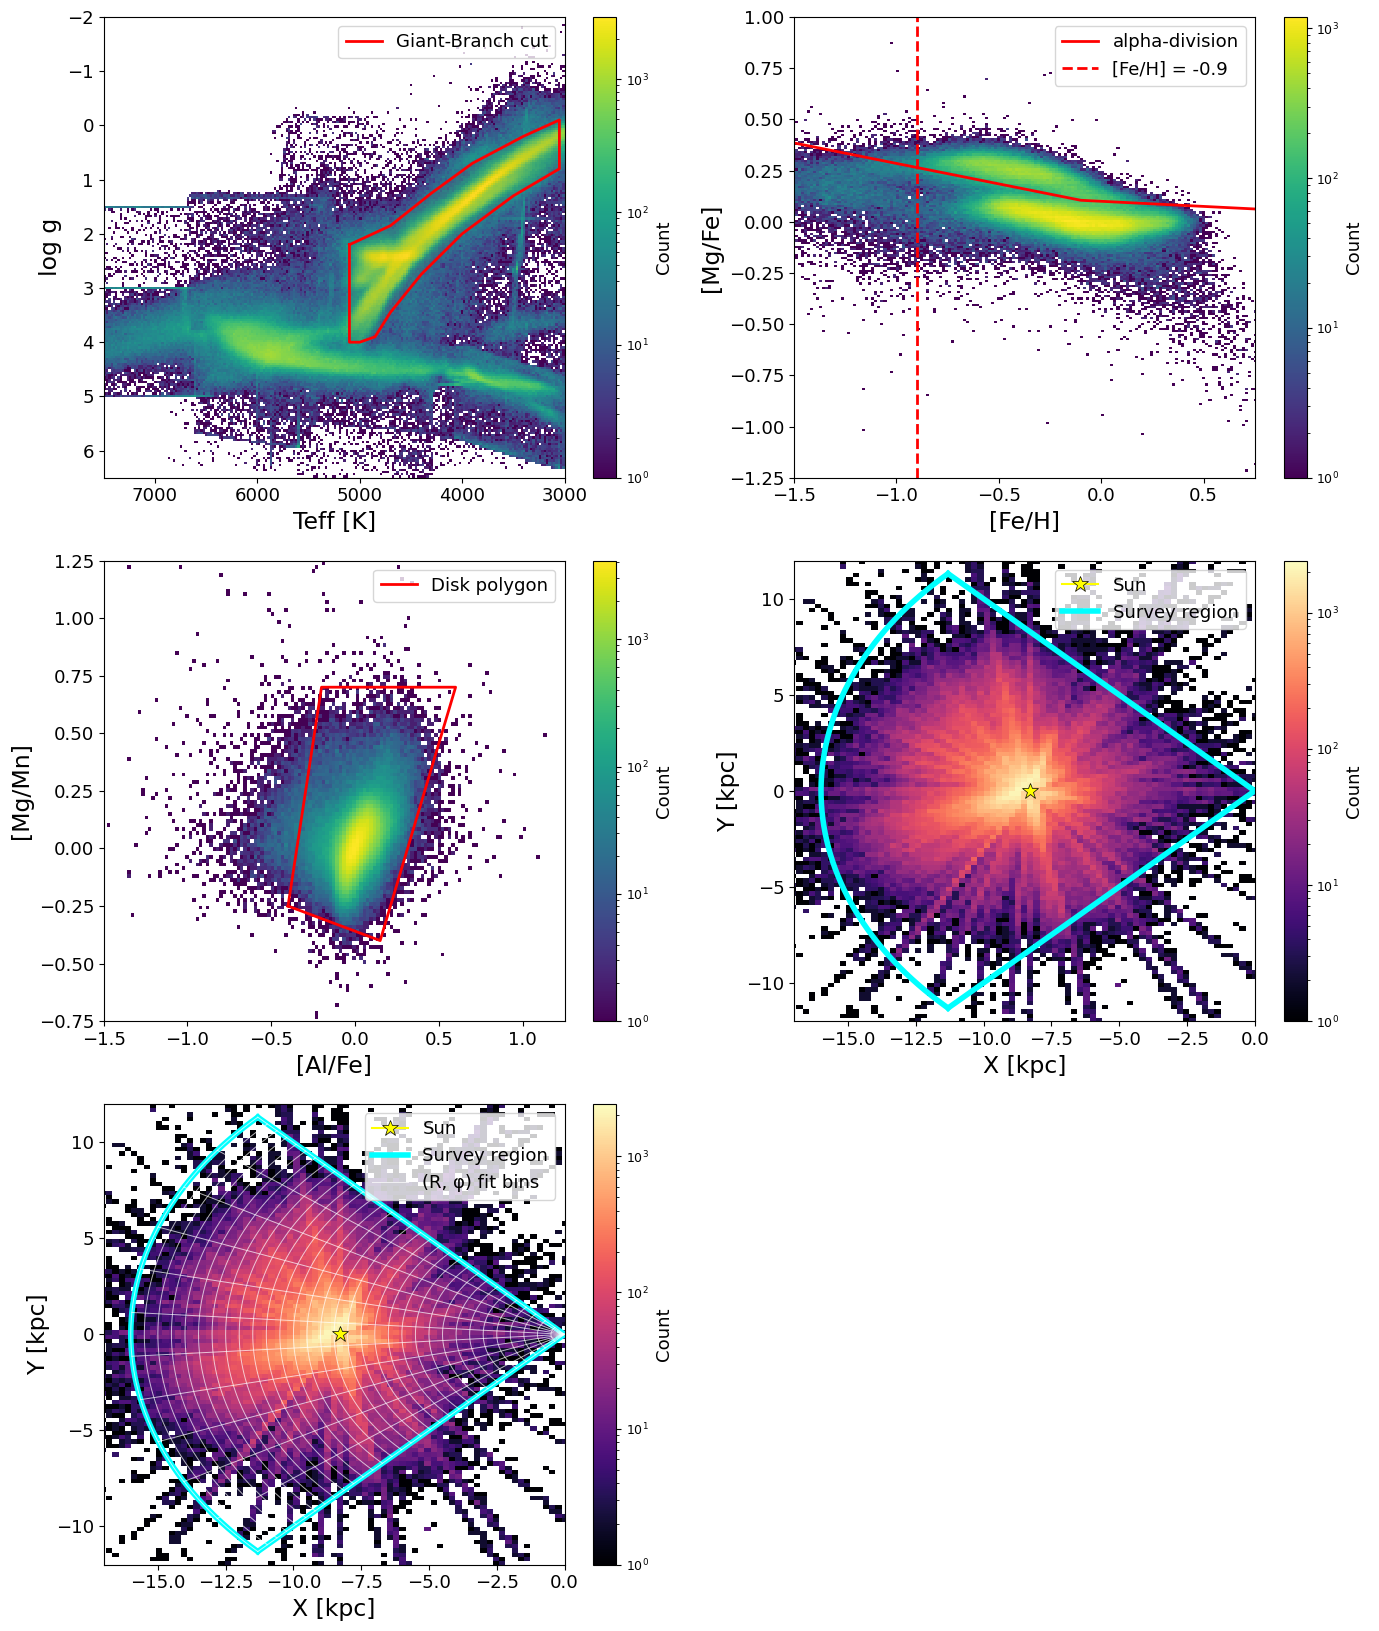

In [189]:
from src.utils import col_to_float_array
t_sel_gb = t[master_mask]
# [Fe/H] and [Mg/Fe] for the giant-branch-only sample (before the low-alpha + metallicity cuts)
fe_gb = col_to_float_array(t_sel_gb, "fe_h")
mgh_gb = col_to_float_array(t_sel_gb, "mg_h")
mgfe_gb = mgh_gb - fe_gb

import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm
from src.config import GB_VERTICES
from src.chemistry import mgfe_dividing_line, FEH_CUT

# pre-chemistry arrays for panel 2
fe_prechem = np.asarray(sel_arrays["feh"], float)
mgfe_prechem = np.asarray(sel_arrays["mgh"], float) - fe_prechem
finite_prechem = np.isfinite(fe_prechem) & np.isfinite(mgfe_prechem)

fig, axes = plt.subplots(3, 2, figsize=(14, 16.5))

plt.rcParams.update({
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
})

# ============================================================
# PANEL 1 (top left): Kiel diagram
# ============================================================
ax = axes[0, 0]
finite_basic = np.isfinite(sel_arrays["teff"]) & np.isfinite(sel_arrays["logg"])
x_all = np.asarray(sel_arrays["teff"], float)[finite_basic]
y_all = np.asarray(sel_arrays["logg"], float)[finite_basic]

h1 = ax.hist2d(
    x_all, y_all,
    bins=200,
    range=[(3000, 7500), (-2, 6.5)],
    norm=LogNorm(),
    cmap="viridis"
)
cb1 = fig.colorbar(h1[3], ax=ax, label="Count")
cb1.set_label("Count", fontsize=13)
cb1.ax.tick_params(labelsize=9)

gb_closed = np.vstack([GB_VERTICES, GB_VERTICES[0]])
ax.plot(gb_closed[:, 0], gb_closed[:, 1], "r-", lw=2, label="Giant-Branch cut")
ax.fill(gb_closed[:, 0], gb_closed[:, 1], color="red", alpha=0.06)

ax.invert_xaxis()
ax.invert_yaxis()
ax.set_xlim(7500, 3000)
ax.set_ylim(6.5, -2)
ax.set_xlabel("Teff [K]")
ax.set_ylabel("log g")
ax.legend(loc="upper right")

# ============================================================
# PANEL 2 (top right): [Mg/Fe] vs [Fe/H] -- all giant branch stars
# ============================================================
ax = axes[0, 1]
h2 = ax.hist2d(
    fe_gb, mgfe_gb,
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
cb2 = fig.colorbar(h2[3], ax=ax, label="Count")
cb2.set_label("Count", fontsize=13)
cb2.ax.tick_params(labelsize=9)

fe_grid = np.linspace(np.nanmin(fe_gb), np.nanmax(fe_gb), 400)
ax.plot(fe_grid, mgfe_dividing_line(fe_grid), color="red", lw=2, label="alpha-division")
ax.axvline(feh_min_extra, color="red", lw=2, ls="--", label=f"[Fe/H] = {feh_min_extra}")
ax.set_xlabel("[Fe/H]")
ax.set_ylabel("[Mg/Fe]")
ax.legend(loc="upper right")
ax.set_xlim(-1.5, 0.75)
ax.set_ylim(-1.25, 1.0)

# ============================================================
# PANEL 3 (middle left): [Al/Fe] vs [Mg/Mn]
# ============================================================
ax = axes[1, 0]
h3 = ax.hist2d(
    final_arrays["x_finite"],
    final_arrays["y_finite"],
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
cb3 = fig.colorbar(h3[3], ax=ax, label="Count")
cb3.set_label("Count", fontsize=13)
cb3.ax.tick_params(labelsize=9)

poly = np.vstack([final_arrays["poly_vertices"], final_arrays["poly_vertices"][0]])
ax.plot(poly[:, 0], poly[:, 1], "r-", lw=2, label="Disk polygon")
ax.set_xlabel("[Al/Fe]")
ax.set_ylabel("[Mg/Mn]")
ax.legend(loc="upper right")
ax.set_xlim(-1.5, 1.25)
ax.set_ylim(-0.75, 1.25)

# ============================================================
# PANEL 4 (middle right): XY density with wedge overlay
# ============================================================
ax = axes[1, 1]
h0 = ax.hist2d(X, Y, bins=200, cmap="magma", norm=mcolors.LogNorm())
cb0 = fig.colorbar(h0[3], ax=ax, label="Count")
cb0.set_label("Count", fontsize=13)
cb0.ax.tick_params(labelsize=9)

ax.plot(-8.275, 0, marker="*", color="yellow", markersize=12,
        markeredgecolor="k", markeredgewidth=0.5, label="Sun", zorder=5)

theta_min_wed = 2.35619449
theta_max_wed = 3.92699082
R_min = 0
R_max = 16.0
theta_arc = np.linspace(theta_min_wed, theta_max_wed, 200)
ax.plot(R_min * np.cos(theta_arc), R_min * np.sin(theta_arc), color="cyan", lw=4)
ax.plot(R_max * np.cos(theta_arc), R_max * np.sin(theta_arc), color="cyan", lw=4)
ax.plot([R_min * np.cos(theta_min_wed), R_max * np.cos(theta_min_wed)],
        [R_min * np.sin(theta_min_wed), R_max * np.sin(theta_min_wed)], color="cyan", lw=4)
ax.plot([R_min * np.cos(theta_max_wed), R_max * np.cos(theta_max_wed)],
        [R_min * np.sin(theta_max_wed), R_max * np.sin(theta_max_wed)], color="cyan", lw=4,
        label="Survey region")
ax.set_xlabel("X [kpc]")
ax.set_ylabel("Y [kpc]")
ax.set_xlim(-17, 0)
ax.set_ylim(-12, 12)
ax.legend(loc="upper right")

# ============================================================
# PANEL 5 (bottom left): same as panel 4, with (R, phi) bin grid overlaid
# ============================================================
ax = axes[2, 0]
h5 = ax.hist2d(X, Y, bins=200, cmap="magma", norm=mcolors.LogNorm())
cb5 = fig.colorbar(h5[3], ax=ax, label="Count")
cb5.set_label("Count", fontsize=13)
cb5.ax.tick_params(labelsize=9)

ax.plot(-8.275, 0, marker="*", color="yellow", markersize=12,
        markeredgecolor="k", markeredgewidth=0.5, label="Sun", zorder=5)

ax.plot(R_min * np.cos(theta_arc), R_min * np.sin(theta_arc), color="cyan", lw=4)
ax.plot(R_max * np.cos(theta_arc), R_max * np.sin(theta_arc), color="cyan", lw=4)
ax.plot([R_min * np.cos(theta_min_wed), R_max * np.cos(theta_min_wed)],
        [R_min * np.sin(theta_min_wed), R_max * np.sin(theta_min_wed)], color="cyan", lw=4)
ax.plot([R_min * np.cos(theta_max_wed), R_max * np.cos(theta_max_wed)],
        [R_min * np.sin(theta_max_wed), R_max * np.sin(theta_max_wed)], color="cyan", lw=4,
        label="Survey region")

# extend the fit-bin radii to the wedge edges just for display (doesn't touch the real R_edges)
R_edges_plot = np.concatenate([[R_min], R_edges, [R_max]])

# radial bin edges
for i, r in enumerate(R_edges_plot):
    ax.plot(r * np.cos(theta_arc), r * np.sin(theta_arc),
            color="white", lw=0.7, alpha=0.7,
            label="(R, φ) fit bins" if i == 0 else None)

# azimuthal segment boundaries (same legend entry as radial bins, so no separate label)
for theta_b in crowd_bounds:
    ax.plot([R_edges_plot[0] * np.cos(theta_b), R_edges_plot[-1] * np.cos(theta_b)],
            [R_edges_plot[0] * np.sin(theta_b), R_edges_plot[-1] * np.sin(theta_b)],
            color="white", lw=0.7, alpha=0.7)

ax.set_xlabel("X [kpc]")
ax.set_ylabel("Y [kpc]")
ax.set_xlim(-17, 0)
ax.set_ylim(-12, 12)
ax.legend(loc="upper right")

axes[2, 1].axis("off")

plt.tight_layout()
plt.show()

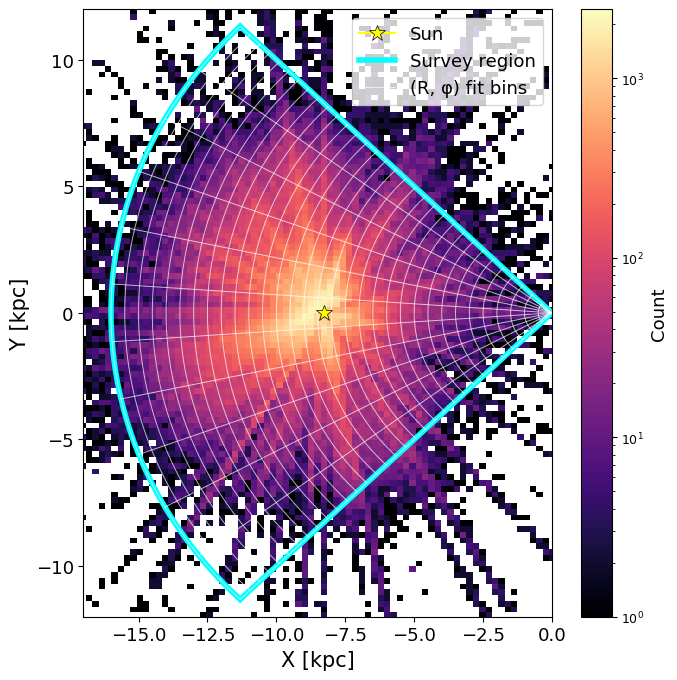

In [305]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

theta_min_wed = 2.35619449
theta_max_wed = 3.92699082
R_min = 0
R_max = 16.0
theta_arc = np.linspace(theta_min_wed, theta_max_wed, 200)

fig, ax = plt.subplots(figsize=(7, 7))

plt.rcParams.update({
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
})

h5 = ax.hist2d(X, Y, bins=200, cmap="magma", norm=mcolors.LogNorm())
cb5 = fig.colorbar(h5[3], ax=ax, label="Count")
cb5.set_label("Count", fontsize=13)
cb5.ax.tick_params(labelsize=9)

ax.plot(-8.275, 0, marker="*", color="yellow", markersize=12,
        markeredgecolor="k", markeredgewidth=0.5, label="Sun", zorder=5)

ax.plot(R_min * np.cos(theta_arc), R_min * np.sin(theta_arc), color="cyan", lw=4)
ax.plot(R_max * np.cos(theta_arc), R_max * np.sin(theta_arc), color="cyan", lw=4)
ax.plot([R_min * np.cos(theta_min_wed), R_max * np.cos(theta_min_wed)],
        [R_min * np.sin(theta_min_wed), R_max * np.sin(theta_min_wed)], color="cyan", lw=4)
ax.plot([R_min * np.cos(theta_max_wed), R_max * np.cos(theta_max_wed)],
        [R_min * np.sin(theta_max_wed), R_max * np.sin(theta_max_wed)], color="cyan", lw=4,
        label="Survey region")

R_edges_plot = np.concatenate([[R_min], R_edges, [R_max]])

for i, r in enumerate(R_edges_plot):
    ax.plot(r * np.cos(theta_arc), r * np.sin(theta_arc),
            color="white", lw=0.7, alpha=0.7,
            label="(R, φ) fit bins" if i == 0 else None)

for theta_b in crowd_bounds:
    ax.plot([R_edges_plot[0] * np.cos(theta_b), R_edges_plot[-1] * np.cos(theta_b)],
            [R_edges_plot[0] * np.sin(theta_b), R_edges_plot[-1] * np.sin(theta_b)],
            color="white", lw=0.7, alpha=0.7)

ax.set_xlabel("X [kpc]")
ax.set_ylabel("Y [kpc]")
ax.set_xlim(-17, 0)
ax.set_ylim(-12, 12)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

## 4. Binning / fit settings

In [15]:
# shared binning + fitting settings
z_edges    = np.linspace(-3.0, 3.0, 181)
mgfe_edges = np.linspace(-0.2, 0.6, 161)
R_edges    = np.arange(0.5, 15.5 + 0.5, 0.5)

minN_seg_total   = 15
min_bin_count    = 5
min_bins_for_fit = 8
z_fit_min, z_fit_max = -1.5, 1.5
zlim = 0.6

R_centers = 0.5 * (R_edges[:-1] + R_edges[1:])

State ready: `t_final`, `star_pack`, `R_star`, `Z_star`, `phi_star`, `mgfe_star`,
`t_star`, `e_mg_h_star`, `e_fe_h_star`, `mgfe_err_star`, `segm`, `crowd_bounds`,
`seg_diag`, `SEG_PLOT`, `SEG_PLOT_heat`, plus the binning settings.

## 5. sech² mixture model

Two-component sech² dip in [Mg/Fe] vs z, with a HalfNormal-parameterized amplitude
(forced negative), an outlier-mixture likelihood (`Q` = outlier fraction), and priors
tuned to the physical scale of the problem (dip depth ~0.05-0.15 dex, z0 within
~0.2 kpc of the plane, thin/thick-disk-like scale heights).

In [16]:
def mixture_of_sech2(z, A1, A2, h1, h2, z0):
    dz = z - z0
    return A1 * (1 / jnp.cosh(dz / h1)) ** 2 + A2 * (1 / jnp.cosh(dz / h2)) ** 2

In [17]:
# def model(data):
#     _A1 = numpyro.sample("_A1", dist.HalfNormal(0.2))
#     _A2 = numpyro.sample("_A2", dist.HalfNormal(0.2))
#     A1 = numpyro.deterministic("A1", -_A1)
#     A2 = numpyro.deterministic("A2", -_A2)

#     h1   = numpyro.sample("h1",   dist.Uniform(0.04, 1.0))
#     d_h2 = numpyro.sample("d_h2", dist.Uniform(0.04, 0.5))
#     h2 = numpyro.deterministic("h2", h1 + d_h2)

#     z0 = numpyro.sample("z0", dist.Normal(0.0, 0.2))

#     offset = numpyro.sample("offset", dist.Normal(0.05, 0.10))

#     model_y = mixture_of_sech2(data["z"], A1, A2, h1, h2, z0) + offset

#     Q = numpyro.sample("Q", dist.TruncatedNormal(0.0, 0.05, low=0, high=1.0))
#     mix = dist.Categorical(probs=jnp.array([Q, 1.0 - Q]))
#     components = [
#         dist.Normal(0.0, jnp.sqrt(1.0**2 + data["mg_fe_err"]**2)),
#         dist.Normal(model_y, data["mg_fe_err"]),
#     ]

#     numpyro.sample(
#         "obs",
#         dist.Mixture(mix, components),
#         obs=data["mg_fe"],
#     )

In [34]:
def model(data):
    _A1 = numpyro.sample("_A1", dist.HalfNormal(.2))
    _A2 = numpyro.sample("_A2", dist.HalfNormal(0.2))
    A1 = numpyro.deterministic("A1", -_A1)
    A2 = numpyro.deterministic("A2", -_A2)

    h1   = numpyro.sample("h1",   dist.Uniform(0.04, 1.0))
    # d_h2 = numpyro.sample("d_h2", dist.Uniform(0.04, 0.5))
    d_h2 = numpyro.sample("d_h2", dist.Uniform(0.04, .75)) 
    h2 = numpyro.deterministic("h2", h1 + d_h2)

    z0 = numpyro.sample("z0", dist.Normal(0.0, 0.2))

    # offset = numpyro.sample("offset", dist.Normal(0.05, 0.10))
    offset = numpyro.sample("offset", dist.Normal(0.0, 0.2))

    model_y = mixture_of_sech2(data["z"], A1, A2, h1, h2, z0) + offset

    Q = numpyro.deterministic("Q", 0.0)
    # Q = numpyro.sample("Q", dist.TruncatedNormal(0.0, 0.05, low=0, high=1.0))
    # # Q = numpyro.sample("Q", dist.TruncatedNormal(0.0, 0.02, low=0, high=0.3))
    mix = dist.Categorical(probs=jnp.array([Q, 1.0 - Q]))
    components = [
        dist.Normal(0.0, jnp.sqrt(1.0**2 + data["mg_fe_err"]**2)),
        dist.Normal(model_y, data["mg_fe_err"]),
    ]

    numpyro.sample(
        "obs",
        dist.Mixture(mix, components),
        obs=data["mg_fe"],
    ) 

## 6. Binning + per-cell fit helpers

`bin_one` bins [Mg/Fe] vs z with inverse-variance weighting plus intrinsic-scatter
inflation. `fit_sech2` runs NUTS (`dense_mass=True`, `target_accept_prob=0.95`,
`init_to_median`) for 1000 warmup / 1000 samples / 2 chains. `select_annulus_segment`
pulls stars for one (R, segment) cell, bins them, and applies the min-count / min-bins
cuts before handing off to the fit.

In [18]:
Z_BINS_FIT = np.arange(-5, 5 + 1e-3, 0.1)


def bin_one(z, mgfe, mgfe_err, z_bins=Z_BINS_FIT):
    """Weighted mean + intrinsic-scatter-inflated error, binned in z."""
    stat1 = binned_statistic(z, mgfe / mgfe_err**2, bins=z_bins, statistic="sum")
    stat2 = binned_statistic(z, 1 / mgfe_err**2, bins=z_bins, statistic="sum")
    stat_std = binned_statistic(z, mgfe, bins=z_bins, statistic="std")
    stat_count = binned_statistic(z, mgfe, bins=z_bins, statistic="count")

    intrinsic_scatter = stat_std.statistic / np.sqrt(stat_count.statistic)

    mean_mg_fe = stat1.statistic / stat2.statistic
    mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
    z_binc = 0.5 * (z_bins[1:] + z_bins[:-1])

    counts = stat_count.statistic
    return z_binc, mean_mg_fe, mean_mg_fe_err, counts


def fit_sech2(z_binc, mean_mg_fe, mean_mg_fe_err, key,
              num_warmup=1000, num_samples=1000, num_chains=2,
              progress_bar=False):
    sampler = infer.MCMC(
        infer.NUTS(
            model,
            dense_mass=True,
            target_accept_prob=0.95,
            init_strategy=infer.init_to_median(num_samples=20),
        ),
        num_warmup=num_warmup, num_samples=num_samples,
        num_chains=num_chains, progress_bar=progress_bar,
    )
    data = {
        "z": jnp.asarray(z_binc),
        "mg_fe": jnp.asarray(mean_mg_fe),
        "mg_fe_err": jnp.asarray(mean_mg_fe_err),
    }
    sampler.run(key, data=data)
    return sampler


def select_annulus_segment(R_use, Z_use, mgfe_use, mgfe_err_use, seg_mask,
                           Rmin, Rmax,
                           min_bin_count=min_bin_count,
                           min_bins_for_fit=min_bins_for_fit,
                           z_fit_min=z_fit_min, z_fit_max=z_fit_max):
    """Select stars, bin, return data ready for MCMC.

    Returns (z_binc, mean_mg_fe, mean_mg_fe_err, n_stars, ok); ok is False if the
    (annulus, segment) doesn't have enough data to fit.
    """
    m = (
        seg_mask
        & (R_use >= Rmin) & (R_use < Rmax)
        & np.isfinite(Z_use) & np.isfinite(mgfe_use)
        & np.isfinite(mgfe_err_use) & (mgfe_err_use > 0)
    )
    n_stars = int(m.sum())
    if n_stars < minN_seg_total:
        return None, None, None, n_stars, False

    z_binc, mean_mg_fe, mean_mg_fe_err, counts = bin_one(
        Z_use[m], mgfe_use[m], mgfe_err_use[m]
    )

    good = (
        np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err)
        & (counts >= min_bin_count)
        & (z_binc >= z_fit_min) & (z_binc <= z_fit_max)
    )
    if good.sum() < min_bins_for_fit:
        return None, None, None, n_stars, False

    return (
        np.asarray(z_binc[good], float),
        np.asarray(mean_mg_fe[good], float),
        np.asarray(mean_mg_fe_err[good], float),
        n_stars,
        True,
    )

## 7. MCMC over (annulus, segment) grid → z₀

Fits every (R, crowded-segment) cell. Loads `sech2_mcmc_results2.pkl` if present;
set `FORCE_RERUN = True` to redo the loop from scratch. This is many fits — after
the first JIT-compiles (~30 s), subsequent fits are a few seconds each.

In [28]:
RESULTS_PATH = "sech2_mcmc_results2.pkl"
FORCE_RERUN  = True    # set True to re-run the loop from scratch

if os.path.exists(RESULTS_PATH) and not FORCE_RERUN:
    with open(RESULTS_PATH, "rb") as f:
        saved = pickle.load(f)
    z0_med   = saved["z0_med"]
    z0_std   = saved["z0_std"]
    n_stars  = saved["n_stars"]
    n_bins   = saved["n_bins"]
    ok_grid  = saved["ok_grid"]
    per_cell = saved["per_cell"]
    print(f"loaded results from {RESULTS_PATH}  "
          f"({int(ok_grid.sum())}/{ok_grid.size} cells)")
else:
    n_R   = len(R_edges) - 1
    n_seg = len(SEG_PLOT_heat)
    z0_med  = np.full((n_R, n_seg), np.nan)
    z0_std  = np.full((n_R, n_seg), np.nan)
    n_stars = np.zeros((n_R, n_seg), dtype=int)
    n_bins  = np.zeros((n_R, n_seg), dtype=int)
    ok_grid = np.zeros((n_R, n_seg), dtype=bool)
    per_cell = {}   # (i_R, j_seg) -> dict with binned data + samples

    key   = jr.PRNGKey(0)
    pairs = list(product(range(n_R), range(n_seg)))

    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin = float(R_edges[i_R]); Rmax = float(R_edges[i_R + 1])
        seg_id = SEG_PLOT_heat[j_seg]
        z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment(
            R_star, Z_star, mgfe_star, mgfe_err_star,
            seg_mask=segm[seg_id], Rmin=Rmin, Rmax=Rmax,
        )
        n_stars[i_R, j_seg] = ns_k
        if not ok_k:
            continue
        n_bins[i_R, j_seg] = len(z_binc_k)
        try:
            key, sub = jr.split(key)
            sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
            samples_k = sampler_k.get_samples()
            z0_med[i_R, j_seg] = float(np.median(samples_k["z0"]))
            z0_std[i_R, j_seg] = float(np.std(samples_k["z0"]))
            ok_grid[i_R, j_seg] = True
            per_cell[(i_R, j_seg)] = {
                "z_binc": np.asarray(z_binc_k),
                "mean":   np.asarray(mean_k),
                "err":    np.asarray(err_k),
                "samples": {kk: np.asarray(vv[:1000]) for kk, vv in samples_k.items()},
            }
        except Exception as e:
            print(f"  fit failed: seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
        if k % 10 == 0 or k == len(pairs):
            print(f"  done {k}/{len(pairs)}", flush=True)

    print("fits complete:", int(ok_grid.sum()), "/", ok_grid.size)

    with open(RESULTS_PATH, "wb") as f:
        pickle.dump({
            "z0_med":   z0_med,
            "z0_std":   z0_std,
            "n_stars":  n_stars,
            "n_bins":   n_bins,
            "ok_grid":  ok_grid,
            "per_cell": per_cell,
            "R_edges":       R_edges,
            "SEG_PLOT_heat": SEG_PLOT_heat,
            "crowd_bounds":  np.asarray(crowd_bounds),
        }, f)
    print(f"saved to {RESULTS_PATH}")

n_R   = len(R_edges) - 1
n_seg = len(SEG_PLOT_heat)

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_59424/2802478694.py:13: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_59424/2802478694.py:14: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_59424/2802478694.py:24: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


  done 40/330
  done 50/330
  done 60/330
  done 70/330
  done 80/330
  done 90/330
  done 120/330
  done 130/330
  done 140/330
  done 150/330
  done 160/330
  done 170/330
  done 180/330
  done 190/330
fits complete: 149 / 330
saved to sech2_mcmc_results2.pkl


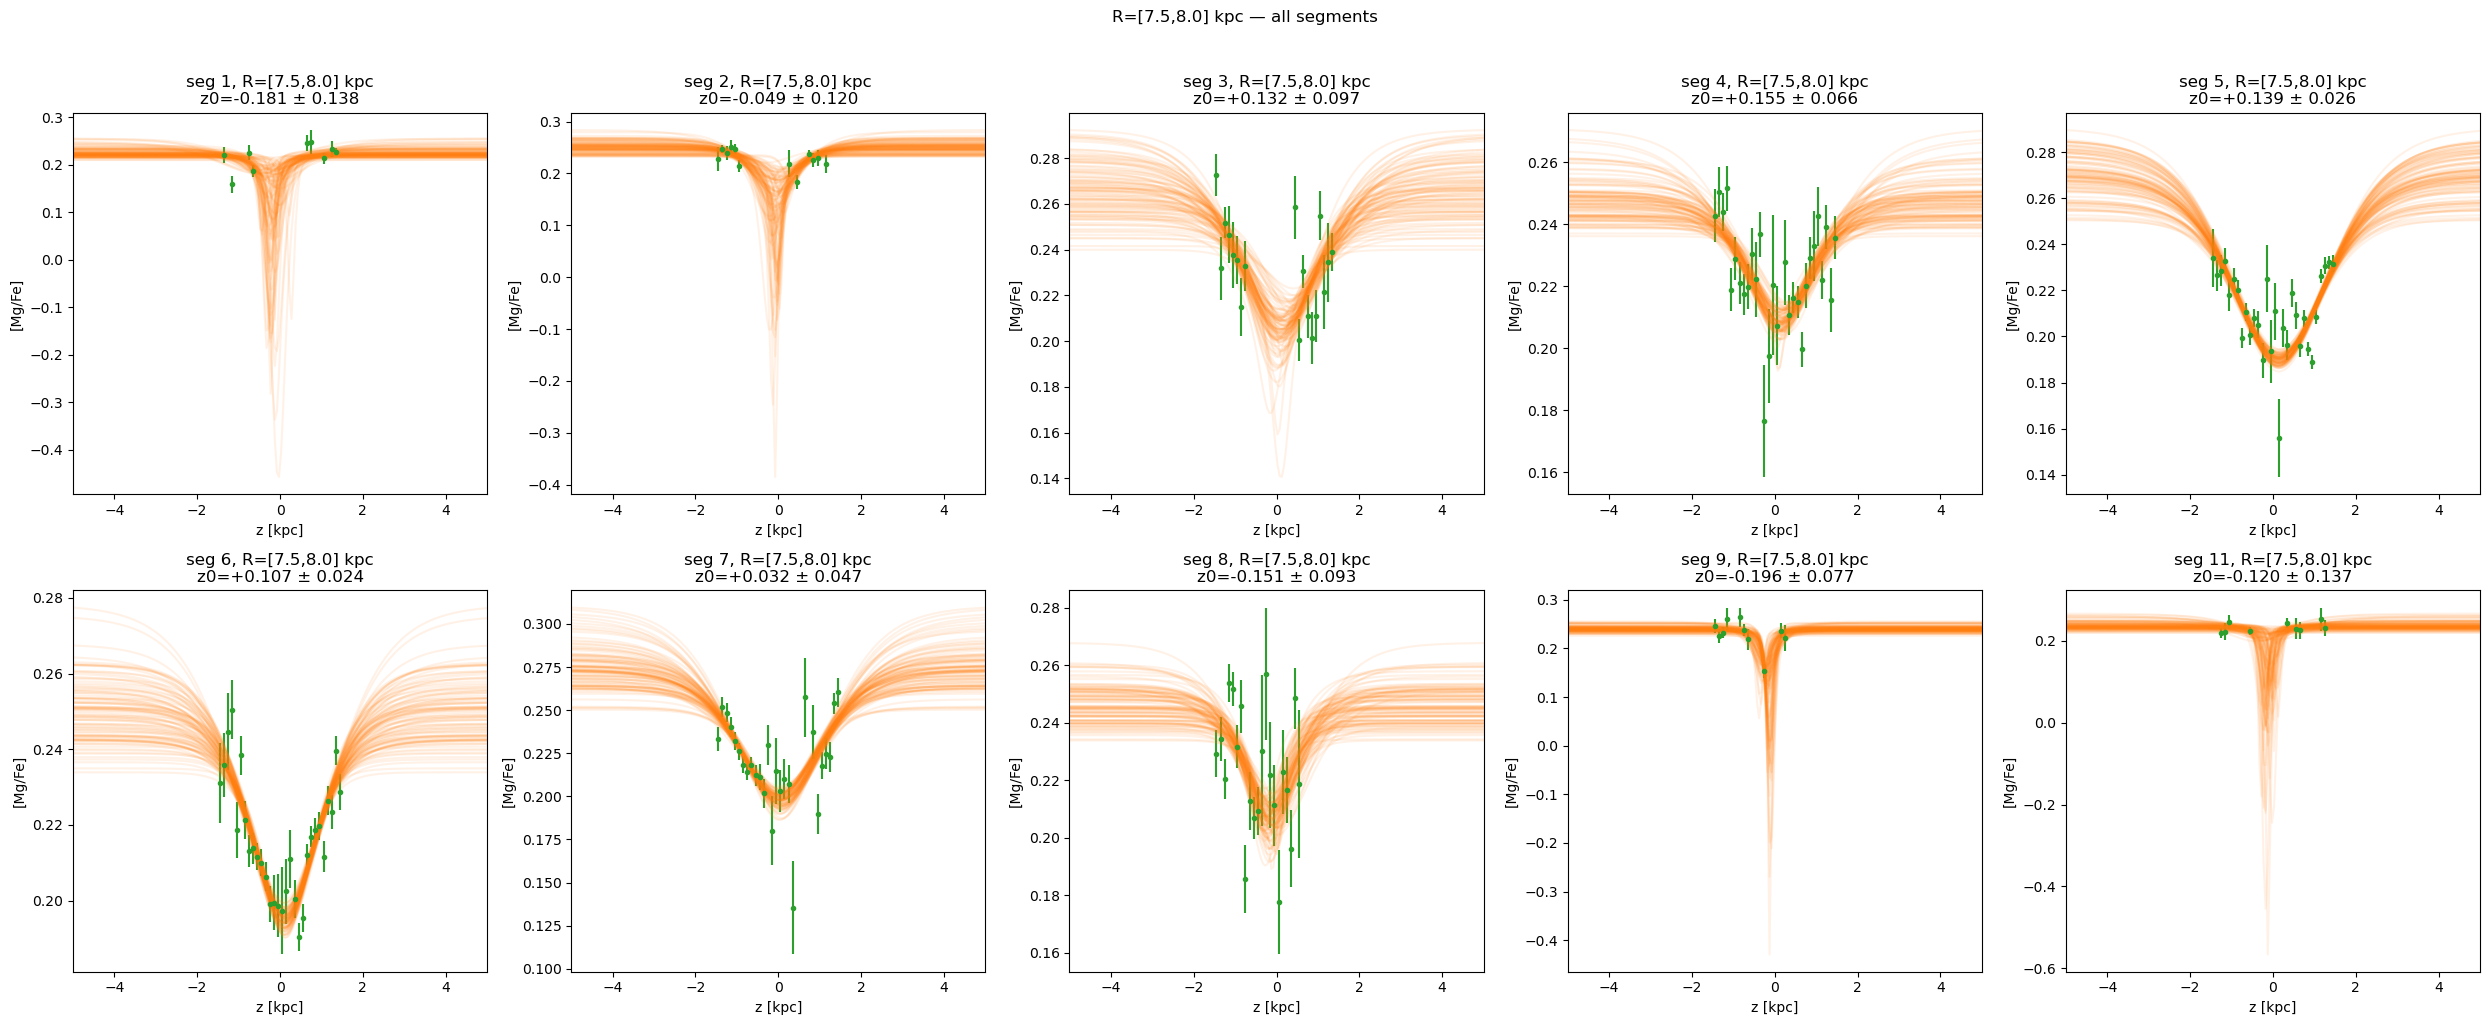

In [29]:
i_R_focus = np.searchsorted(R_edges, 7.5)  
cells_in_R = [(i_R, j_seg) for (i_R, j_seg) in per_cell.keys() if i_R == i_R_focus]
n_cells = len(cells_in_R)
n_cols = 5
n_rows = int(np.ceil(n_cells / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), squeeze=False)
z_grid = np.linspace(-5, 5, 200)

for idx, (i_R, j_seg) in enumerate(cells_in_R):
    r, c = divmod(idx, n_cols)
    ax = axes[r, c]
    cell = per_cell[(i_R, j_seg)]
    seg_id = SEG_PLOT_heat[j_seg]
    s = cell["samples"]

    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                color="C2", linestyle="", marker=".", label="binned mean")

    for i in range(min(100, len(s["A1"]))):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        y_pred = mixture_of_sech2(z_grid, cell_sample["A1"], cell_sample["A2"],
                                  cell_sample["h1"], cell_sample["h2"],
                                  cell_sample["z0"]) + cell_sample["offset"]
        ax.plot(z_grid, y_pred, color="C1", alpha=0.1)

    ax.set_xlabel("z [kpc]")
    ax.set_ylabel("[Mg/Fe]")
    ax.set_title(f"seg {seg_id}, R=[{R_edges[i_R]:.1f},{R_edges[i_R+1]:.1f}] kpc\n"
                 f"z0={z0_med[i_R,j_seg]:+.3f} \u00b1 {z0_std[i_R,j_seg]:.3f}")
    ax.set_xlim(-5, 5)

for idx in range(n_cells, n_rows * n_cols):
    r, c = divmod(idx, n_cols)
    axes[r, c].axis("off")

plt.suptitle(f"R=[{R_edges[i_R_focus]:.1f},{R_edges[i_R_focus+1]:.1f}] kpc \u2014 all segments", y=1.02)
plt.tight_layout()
plt.show()

In [30]:
from matplotlib.backends.backend_pdf import PdfPages

n_R = len(R_edges) - 1
z_grid = np.linspace(-5, 5, 200)
n_cols = 5

with PdfPages("sech2_fits_all_segments.pdf") as pdf:
    for i_R_focus in range(n_R):
        cells_in_R = [(i_R, j_seg) for (i_R, j_seg) in per_cell.keys() if i_R == i_R_focus]
        n_cells = len(cells_in_R)

        if n_cells == 0:
            continue  # skip R bins with no fitted cells

        n_rows = int(np.ceil(n_cells / n_cols))
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), squeeze=False)

        for idx, (i_R, j_seg) in enumerate(cells_in_R):
            r, c = divmod(idx, n_cols)
            ax = axes[r, c]
            cell = per_cell[(i_R, j_seg)]
            seg_id = SEG_PLOT_heat[j_seg]
            s = cell["samples"]

            ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                        color="C2", linestyle="", marker=".", label="binned mean")

            for i in range(min(100, len(s["A1"]))):
                cell_sample = {k: v[i] for k, v in s.items()}
                cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
                y_pred = mixture_of_sech2(z_grid, cell_sample["A1"], cell_sample["A2"],
                                          cell_sample["h1"], cell_sample["h2"],
                                          cell_sample["z0"]) + cell_sample["offset"]
                ax.plot(z_grid, y_pred, color="C1", alpha=0.1)

            ax.set_xlabel("z [kpc]")
            ax.set_ylabel("[Mg/Fe]")
            ax.set_title(f"seg {seg_id}, R=[{R_edges[i_R]:.1f},{R_edges[i_R+1]:.1f}] kpc\n"
                         f"z0={z0_med[i_R,j_seg]:+.3f} \u00b1 {z0_std[i_R,j_seg]:.3f}")
            ax.set_xlim(-5, 5)

        for idx in range(n_cells, n_rows * n_cols):
            r, c = divmod(idx, n_cols)
            axes[r, c].axis("off")

        plt.tight_layout()

        pdf.savefig(fig)
        plt.close(fig)  # close instead of show, so it doesn't flood notebook output

print("saved sech2_fits_all_segments.pdf")

saved sech2_fits_all_segments.pdf


Sun's azimuth falls in segment 6 (index 5)


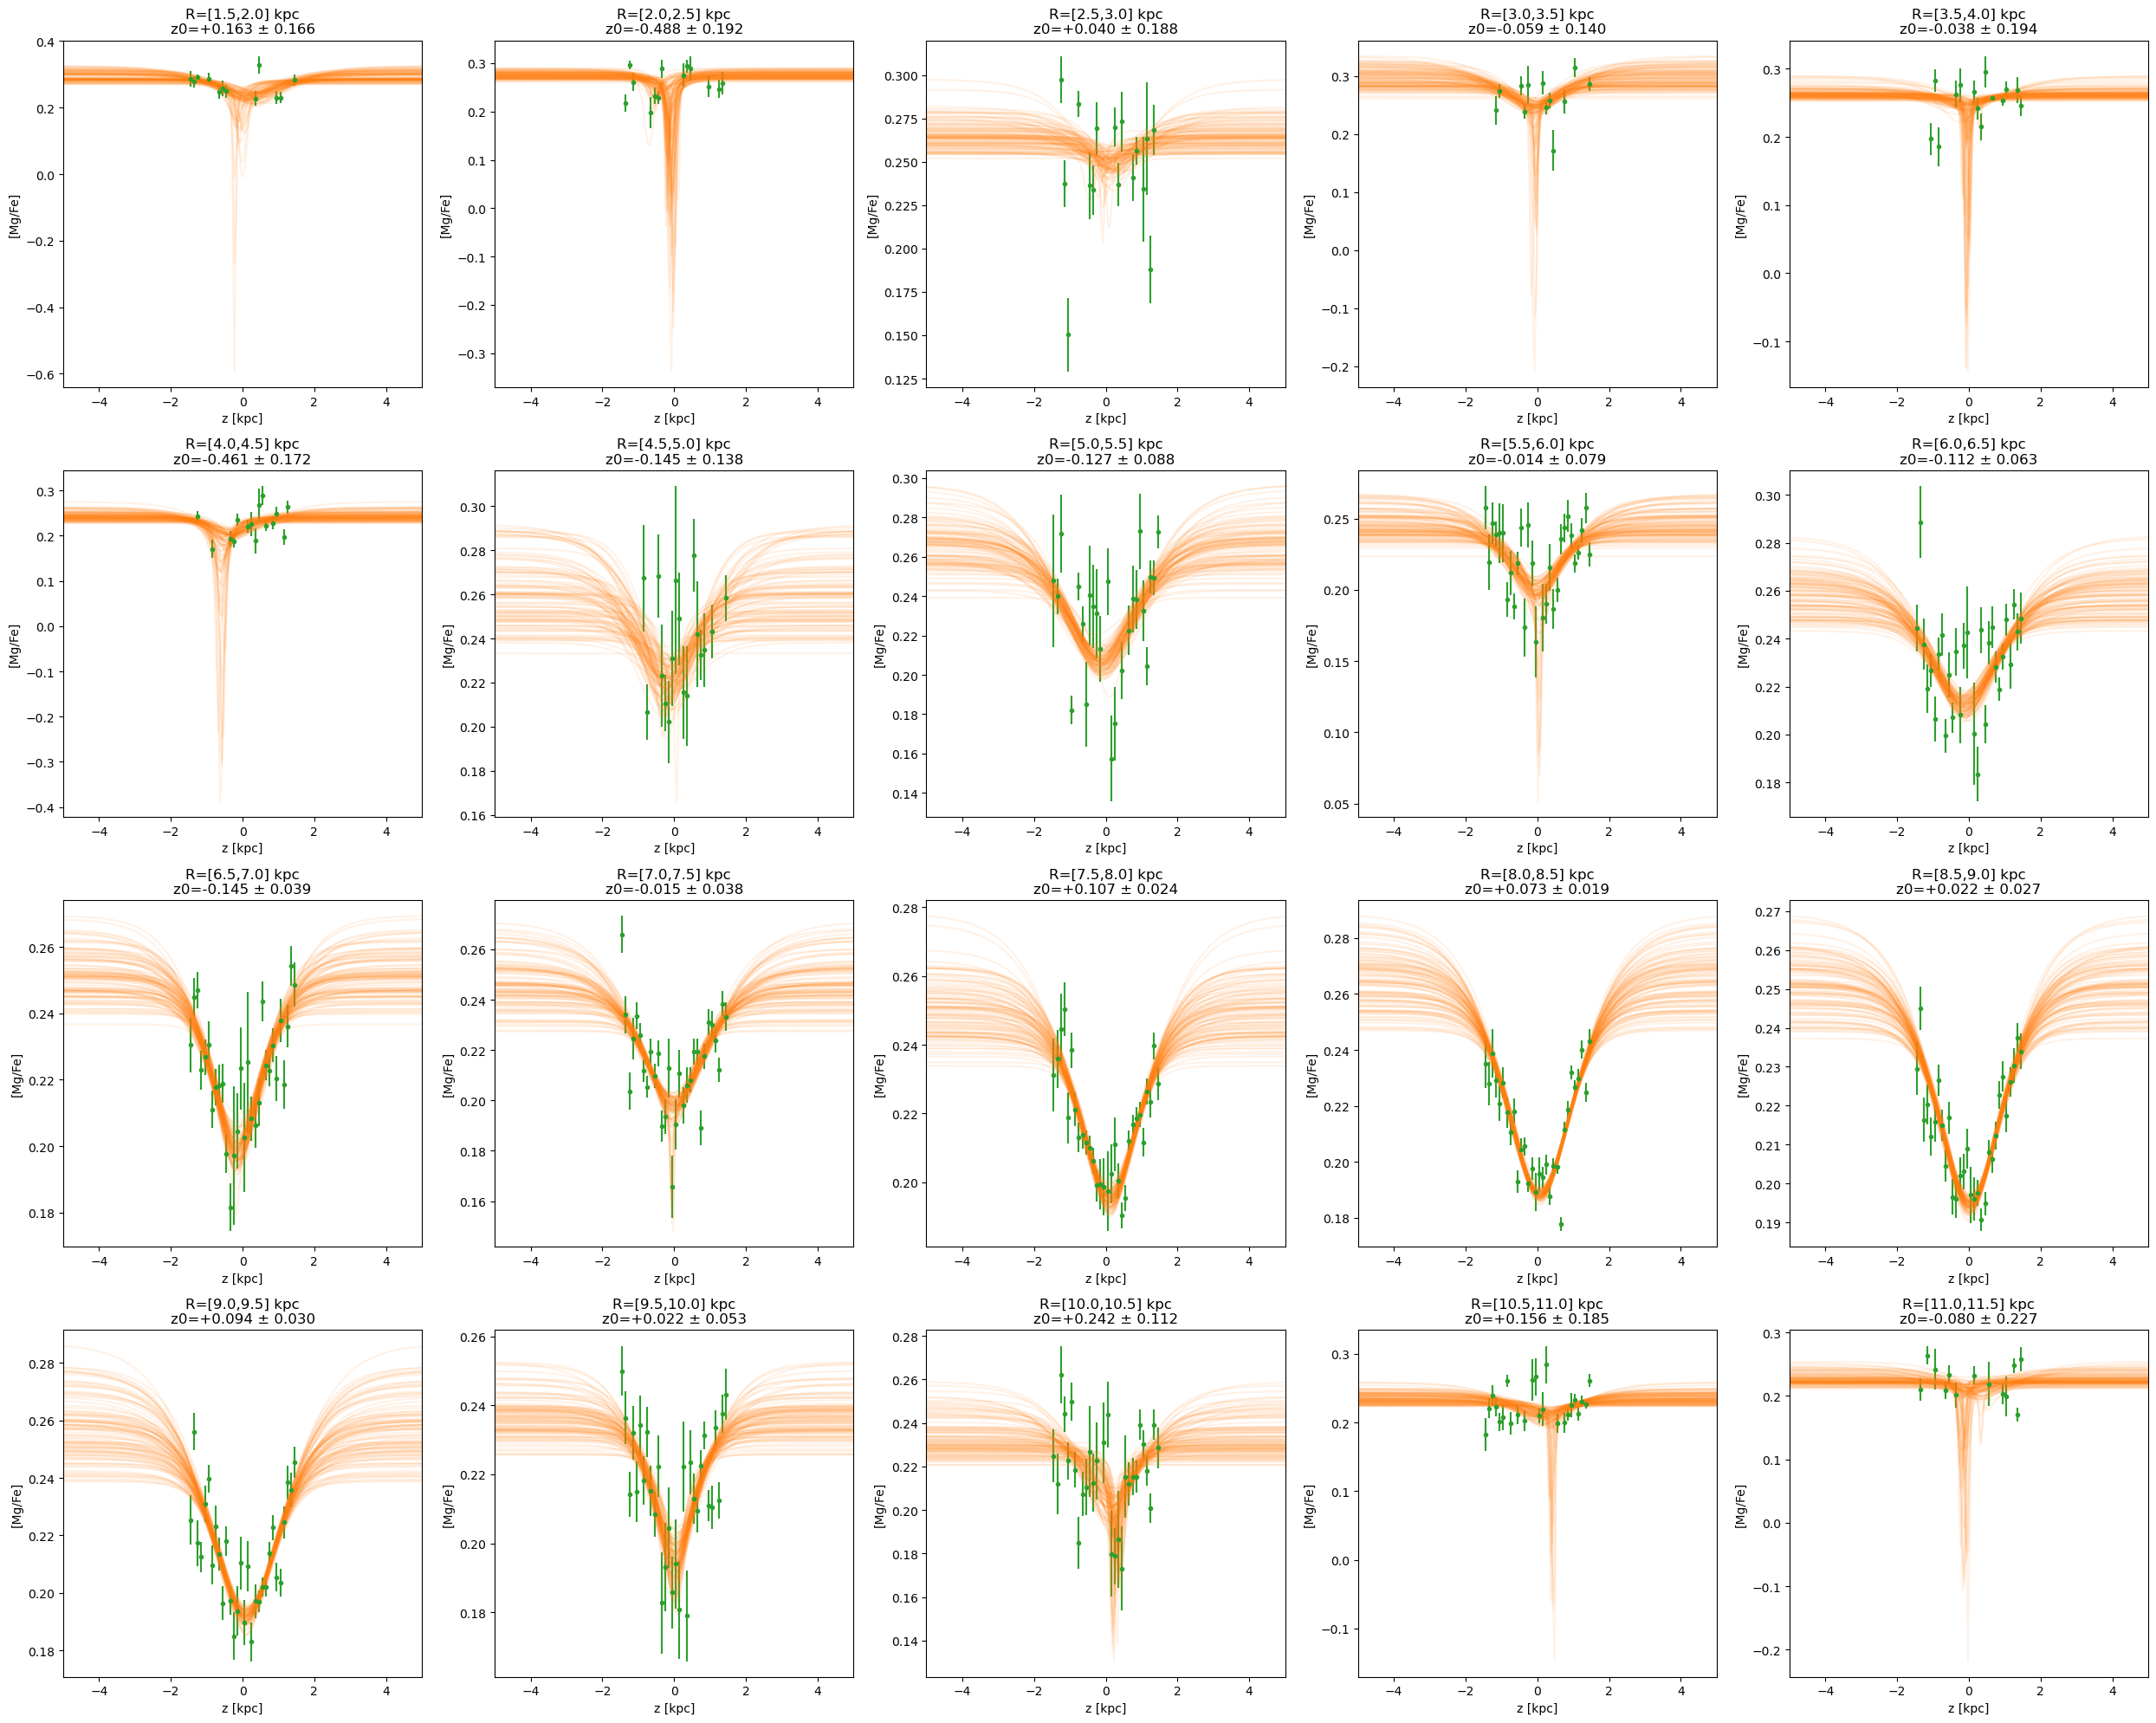

In [31]:
from src.coords import between_ccw

theta_sun = np.radians(180)

# find which segment contains the Sun's azimuth
j_seg_focus = None
for idx, seg_id in enumerate(SEG_PLOT_heat):
    a, b = crowd_bounds[idx], crowd_bounds[idx + 1]
    if between_ccw(np.array([theta_sun]), a, b)[0]:
        j_seg_focus = idx
        seg_id_focus = seg_id
        break

print(f"Sun's azimuth falls in segment {seg_id_focus} (index {j_seg_focus})")

n_R = len(R_edges) - 1
cells_in_seg = [(i_R, j_seg) for (i_R, j_seg) in per_cell.keys() if j_seg == j_seg_focus]
cells_in_seg.sort(key=lambda x: x[0])  # order by radius
n_cells = len(cells_in_seg)

n_cols = 5
n_rows = int(np.ceil(n_cells / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), squeeze=False)
z_grid = np.linspace(-5, 5, 200)

for idx, (i_R, j_seg) in enumerate(cells_in_seg):
    r, c = divmod(idx, n_cols)
    ax = axes[r, c]
    cell = per_cell[(i_R, j_seg)]
    s = cell["samples"]

    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                color="C2", linestyle="", marker=".", label="binned mean")

    for i in range(min(100, len(s["A1"]))):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        y_pred = mixture_of_sech2(z_grid, cell_sample["A1"], cell_sample["A2"],
                                  cell_sample["h1"], cell_sample["h2"],
                                  cell_sample["z0"]) + cell_sample["offset"]
        ax.plot(z_grid, y_pred, color="C1", alpha=0.1)

    ax.set_xlabel("z [kpc]")
    ax.set_ylabel("[Mg/Fe]")
    ax.set_title(f"R=[{R_edges[i_R]:.1f},{R_edges[i_R+1]:.1f}] kpc\n"
                 f"z0={z0_med[i_R,j_seg]:+.3f} \u00b1 {z0_std[i_R,j_seg]:.3f}")
    ax.set_xlim(-5, 5)

for idx in range(n_cells, n_rows * n_cols):
    r, c = divmod(idx, n_cols)
    axes[r, c].axis("off")

plt.tight_layout()
plt.show()

Sun's position falls in segment 6 (index 5), R bin [8.0,8.5] kpc


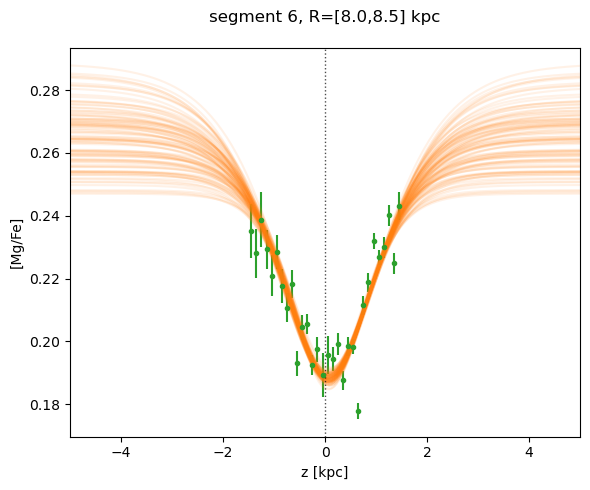

In [32]:
from src.coords import between_ccw

theta_sun = np.radians(180)
R_sun = 8.275

# find the segment containing the Sun's azimuth
j_seg_focus = None
for idx, seg_id in enumerate(SEG_PLOT_heat):
    a, b = crowd_bounds[idx], crowd_bounds[idx + 1]
    if between_ccw(np.array([theta_sun]), a, b)[0]:
        j_seg_focus = idx
        seg_id_focus = seg_id
        break

# find the radial bin containing the Sun's radius
i_R_focus = np.searchsorted(R_edges, R_sun) - 1

print(f"Sun's position falls in segment {seg_id_focus} (index {j_seg_focus}), "
      f"R bin [{R_edges[i_R_focus]:.1f},{R_edges[i_R_focus+1]:.1f}] kpc")

cell = per_cell[(i_R_focus, j_seg_focus)]
s = cell["samples"]
z_grid = np.linspace(-5, 5, 200)

fig, ax = plt.subplots(figsize=(6, 5))

ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
            color="C2", linestyle="", marker=".", label="binned mean")

for i in range(min(100, len(s["A1"]))):
    cell_sample = {k: v[i] for k, v in s.items()}
    cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
    y_pred = mixture_of_sech2(z_grid, cell_sample["A1"], cell_sample["A2"],
                              cell_sample["h1"], cell_sample["h2"],
                              cell_sample["z0"]) + cell_sample["offset"]
    ax.plot(z_grid, y_pred, color="C1", alpha=0.1)

ax.axvline(0, color="k", linestyle=":", linewidth=1, alpha=0.7)

ax.set_xlabel("z [kpc]")
ax.set_ylabel("[Mg/Fe]")
ax.set_title(f"segment 6, R=[{R_edges[i_R_focus]:.1f},{R_edges[i_R_focus+1]:.1f}] kpc\n"
             )
ax.set_xlim(-5, 5)

plt.tight_layout()
plt.show()

## 8. Polar heatmaps

Build `theta_edges` from `crowd_bounds`, then plot z₀ (median + stddev) as a polar
`pcolormesh` over (R, θ), with the Sun marked. Followed by the same treatment for
h₁, h₂, Q (outlier fraction), and the A1/A2 amplitude ratio.

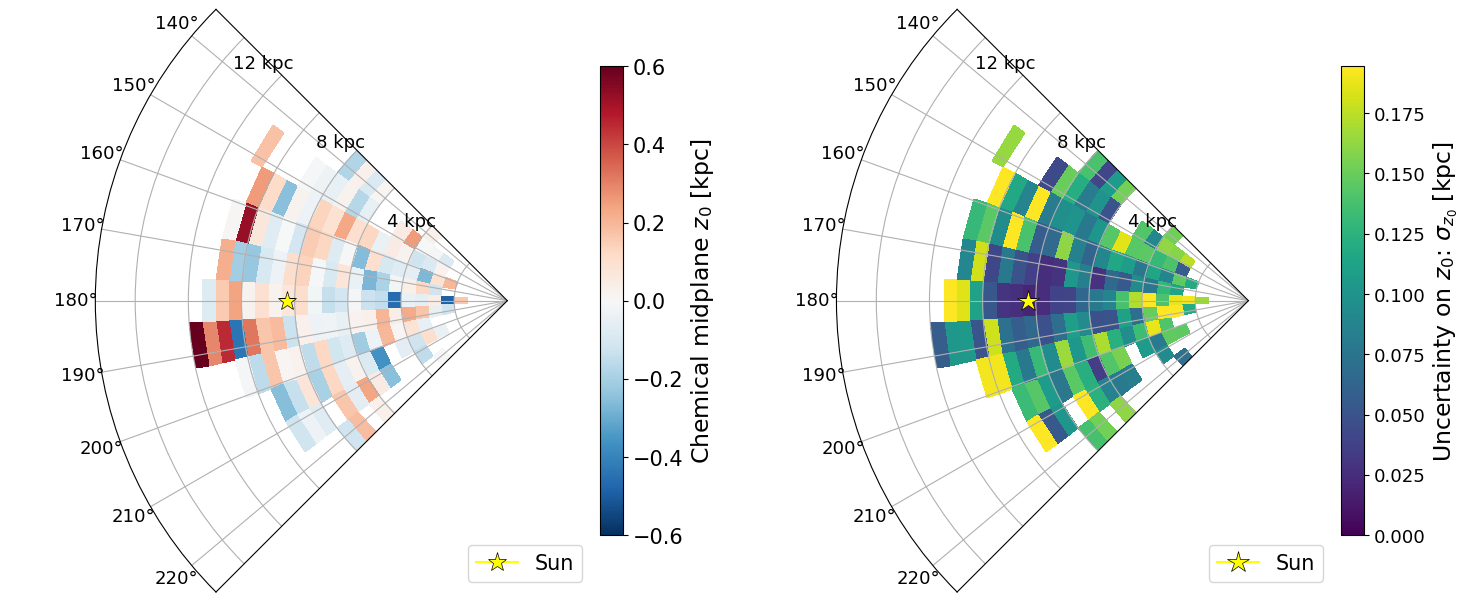

In [33]:
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi
assert len(theta_edges) - 1 == n_seg, "theta_edges length must match number of crowded segments"

T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
Zmap_med = np.ma.masked_invalid(z0_med)
Zmap_std = np.ma.masked_invalid(z0_std)
std_max = float(np.nanpercentile(z0_std[np.isfinite(z0_std)], 95)) if np.isfinite(z0_std).any() else 1.0
theta_min = theta_edges[0]
theta_max = theta_edges[-1]
theta_sun = np.radians(180)  # Sun at phi=180 in Galactocentric convention
R_sun = 8.275

fig = plt.figure(figsize=(15, 7))

# left: z0 median
ax1 = plt.subplot(1, 2, 1, projection="polar")
pcm1 = ax1.pcolormesh(T_mesh, R_mesh, Zmap_med, cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
cb1 = fig.colorbar(pcm1, ax=ax1, pad=0.01, shrink=0.7)
cb1.set_label(r"Chemical midplane $z_0$ [kpc]", fontsize=17)
cb1.ax.tick_params(labelsize=15)
ax1.tick_params(labelsize=13)
ax1.set_theta_zero_location("E")
ax1.set_theta_direction(1)
ax1.set_rmax(R_edges[-1])
ax1.set_thetamin(np.degrees(theta_min))
ax1.set_thetamax(np.degrees(theta_max))
ax1.set_title("")
for r in R_edges[R_edges % 4 == 0]:
    ax1.text(theta_min - np.radians(3), r, f"{r:.0f} kpc",
             fontsize=13, ha="right", va="center")
ax1.set_yticklabels([])
ax1.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=14,
         markeredgecolor="k", markeredgewidth=0.5, zorder=5, label="Sun")
ax1.legend(loc="lower right", fontsize=15)

# right: z0 stddev
ax2 = plt.subplot(1, 2, 2, projection="polar")
pcm2 = ax2.pcolormesh(T_mesh, R_mesh, Zmap_std, cmap="viridis",
                      vmin=0.0, vmax=std_max, shading="flat")
cb2 = fig.colorbar(pcm2, ax=ax2, pad=0.01, shrink=0.7)
cb2.set_label(r"Uncertainty on $z_0$: $\sigma_{z_0}$ [kpc]", fontsize=17)
cb2.ax.tick_params(labelsize=13)
ax2.set_theta_zero_location("E")
ax2.set_theta_direction(1)
ax2.tick_params(labelsize=13)
ax2.set_rmax(R_edges[-1])
ax2.set_thetamin(np.degrees(theta_min))
ax2.set_thetamax(np.degrees(theta_max))
ax2.set_title("")
for r in R_edges[R_edges % 4 == 0]:
    ax2.text(theta_min - np.radians(3), r, f"{r:.0f} kpc",
             fontsize=13, ha="right", va="center")
ax2.set_yticklabels([])
ax2.plot(theta_sun, R_sun, marker="*", color="yellow", markersize=16,
         markeredgecolor="k", markeredgewidth=0.5, zorder=5, label="Sun")
ax2.legend(loc="lower right", fontsize=15)

plt.tight_layout()
plt.show()

## h_eff troubleshooting

In [24]:
def mixture_of_sech2(z, A1, A2, h1, h2, z0):
    dz = z - z0
    return A1 * (1 / jnp.cosh(dz / h1)) ** 2 + A2 * (1 / jnp.cosh(dz / h2)) ** 2

In [25]:
def model(data):
    _A1 = numpyro.sample("_A1", dist.HalfNormal(.2))
    _A2 = numpyro.sample("_A2", dist.HalfNormal(0.2))
    A1 = numpyro.deterministic("A1", -_A1)
    A2 = numpyro.deterministic("A2", -_A2)

    h1   = numpyro.sample("h1",   dist.Uniform(0.04, 1.0))
    # d_h2 = numpyro.sample("d_h2", dist.Uniform(0.04, 0.5))
    d_h2 = numpyro.sample("d_h2", dist.Uniform(0.04, .75)) 
    h2 = numpyro.deterministic("h2", h1 + d_h2)

    z0 = numpyro.sample("z0", dist.Normal(0.0, 0.2))

    # offset = numpyro.sample("offset", dist.Normal(0.05, 0.10))
    offset = numpyro.sample("offset", dist.Normal(0.0, 0.2))

    model_y = mixture_of_sech2(data["z"], A1, A2, h1, h2, z0) + offset

    Q = numpyro.deterministic("Q", 0.0)
    # Q = numpyro.sample("Q", dist.TruncatedNormal(0.0, 0.05, low=0, high=1.0))
    # # Q = numpyro.sample("Q", dist.TruncatedNormal(0.0, 0.02, low=0, high=0.3))
    mix = dist.Categorical(probs=jnp.array([Q, 1.0 - Q]))
    components = [
        dist.Normal(0.0, jnp.sqrt(1.0**2 + data["mg_fe_err"]**2)),
        dist.Normal(model_y, data["mg_fe_err"]),
    ]

    numpyro.sample(
        "obs",
        dist.Mixture(mix, components),
        obs=data["mg_fe"],
    ) 

In [26]:
from tqdm import tqdm
import jax
import jax.random as jr

R_centers_flare = np.arange(4, 15+1e-3, 0.5)
R_width = 1.0
n_R_flare = len(R_centers_flare)

R_arr     = np.asarray(R_star)
Z_arr     = np.asarray(Z_star)
mgfe_arr  = np.asarray(mgfe_star)
err_arr   = np.asarray(mgfe_err_star)

m_base = (
    np.isfinite(R_arr) & np.isfinite(Z_arr)
    & np.isfinite(mgfe_arr) & np.isfinite(err_arr)
    & (err_arr > 0)
)

# store results
per_R_flare = {}
key = jr.PRNGKey(0)

for i_R in tqdm(range(n_R_flare), desc="fitting radial bins"):
    Rlo = R_centers_flare[i_R] - R_width / 2
    Rhi = R_centers_flare[i_R] + R_width / 2

    m = m_base & (R_arr >= Rlo) & (R_arr < Rhi)
    n_stars = int(m.sum())

    if n_stars < minN_seg_total:
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: skipping, only {n_stars} stars")
        continue

    z_binc, mean_mg_fe, mean_mg_fe_err, counts = bin_one(
        Z_arr[m], mgfe_arr[m], err_arr[m]
    )

    good = (
        np.isfinite(mean_mg_fe) & np.isfinite(mean_mg_fe_err)
        & (counts >= min_bin_count)
        & (z_binc >= z_fit_min) & (z_binc <= z_fit_max)
    )

    if good.sum() < min_bins_for_fit:
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: skipping, only {good.sum()} good bins")
        continue

    try:
        key, sub = jr.split(key)
        sampler = fit_sech2(
            np.asarray(z_binc[good], float),
            np.asarray(mean_mg_fe[good], float),
            np.asarray(mean_mg_fe_err[good], float),
            sub,
            progress_bar=False
        )
        samples = sampler.get_samples()
        per_R_flare[i_R] = {
            "Rlo": Rlo, "Rhi": Rhi,
            "n_stars": n_stars,
            "z_binc": np.asarray(z_binc[good]),
            "mean": np.asarray(mean_mg_fe[good]),
            "err": np.asarray(mean_mg_fe_err[good]),
            "samples": {k: np.asarray(v) for k, v in samples.items()},
        }
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: fit ok, n_stars={n_stars}")
    except Exception as e:
        print(f"R=[{Rlo:.1f},{Rhi:.1f}]: fit failed -> {e}")

print(f"fits complete: {len(per_R_flare)}/{n_R_flare}")

import pickle

# save
with open("per_R_flare7.pkl", "wb") as f:
    pickle.dump(per_R_flare, f)

fitting radial bins:   0%|                               | 0/23 [00:00<?, ?it/s]/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_59424/2802478694.py:13: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_59424/2802478694.py:14: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_59424/2802478694.py:24: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(
fitting radial bins:   4%|█                      | 1/23 [00:05<02:04,  5.65s/it]

R=[3.5,4.5]: fit ok, n_stars=5985


fitting radial bins:   9%|██                     | 2/23 [00:10<01:54,  5.45s/it]

R=[4.0,5.0]: fit ok, n_stars=6418


fitting radial bins:  13%|███                    | 3/23 [00:17<01:54,  5.72s/it]

...

R=[12.5,13.5]: fit ok, n_stars=563


fitting radial bins:  87%|███████████████████▏  | 20/23 [01:35<00:11,  3.92s/it]

R=[13.0,14.0]: fit ok, n_stars=328


fitting radial bins: 100%|██████████████████████| 23/23 [01:39<00:00,  4.32s/it]

R=[13.5,14.5]: fit ok, n_stars=205
R=[14.0,15.0]: skipping, only 4 good bins
R=[14.5,15.5]: skipping, only 1 good bins
fits complete: 21/23


loaded 21 radial bins


computing h_eff: 100%|██████████████████████████| 21/21 [00:08<00:00,  2.58it/s]


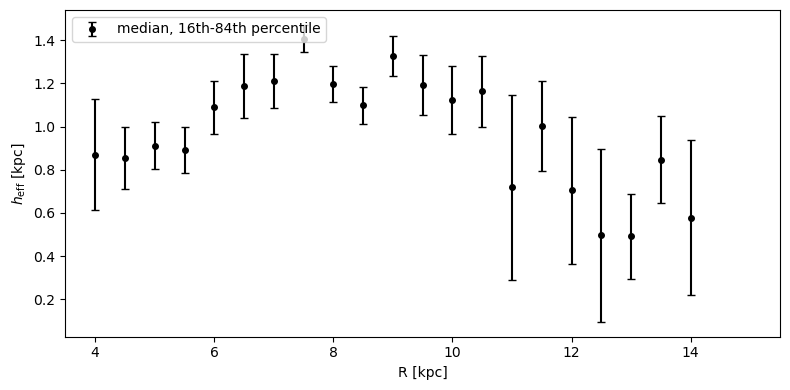

In [27]:
import pickle
import numpy as np
from scipy.optimize import brentq

with open("per_R_flare7.pkl", "rb") as f:
    per_R_flare = pickle.load(f)
print(f"loaded {len(per_R_flare)} radial bins")

R_centers_flare = np.arange(4, 15 + 1e-3, 0.5)
n_R_flare = len(R_centers_flare)
R_width = 1.0

def root_func(z, pars):
    Ystar = mixture_of_sech2(
        z, pars["A1"], pars["A2"], pars["h1"], pars["h2"], pars["z0"]
    )
    return Ystar - 0.5 * (pars["A1"] + pars["A2"])

h_eff_med_flare = np.full(n_R_flare, np.nan)
h_eff_std_flare = np.full(n_R_flare, np.nan)

for i_R, cell in tqdm(per_R_flare.items(), desc="computing h_eff"):
    s = cell["samples"]
    h_effs = []
    for i in range(256):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        hi = 8 * max(cell_sample["h1"], cell_sample["h2"])
        try:
            zstar = brentq(root_func, cell_sample["z0"] + 1e-9, hi, args=(cell_sample,))
            h_effs.append(zstar - cell_sample["z0"])
        except ValueError:
            continue

    if len(h_effs) > 0:
        h_effs = np.array(h_effs)
        h_eff_med_flare[i_R] = np.median(h_effs)
        pcl = np.percentile(h_effs, [16, 84])
        h_eff_std_flare[i_R] = 0.5 * (pcl[1] - pcl[0])

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(R_centers_flare, h_eff_med_flare, yerr=h_eff_std_flare,
            fmt="o", color="k", ms=4, capsize=3,
            label="median, 16th-84th percentile")
ax.legend(loc="upper left")
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]")
ax.set_xlim(R_centers_flare[0] - R_width/2, R_centers_flare[-1] + R_width/2)
plt.tight_layout()
plt.show()

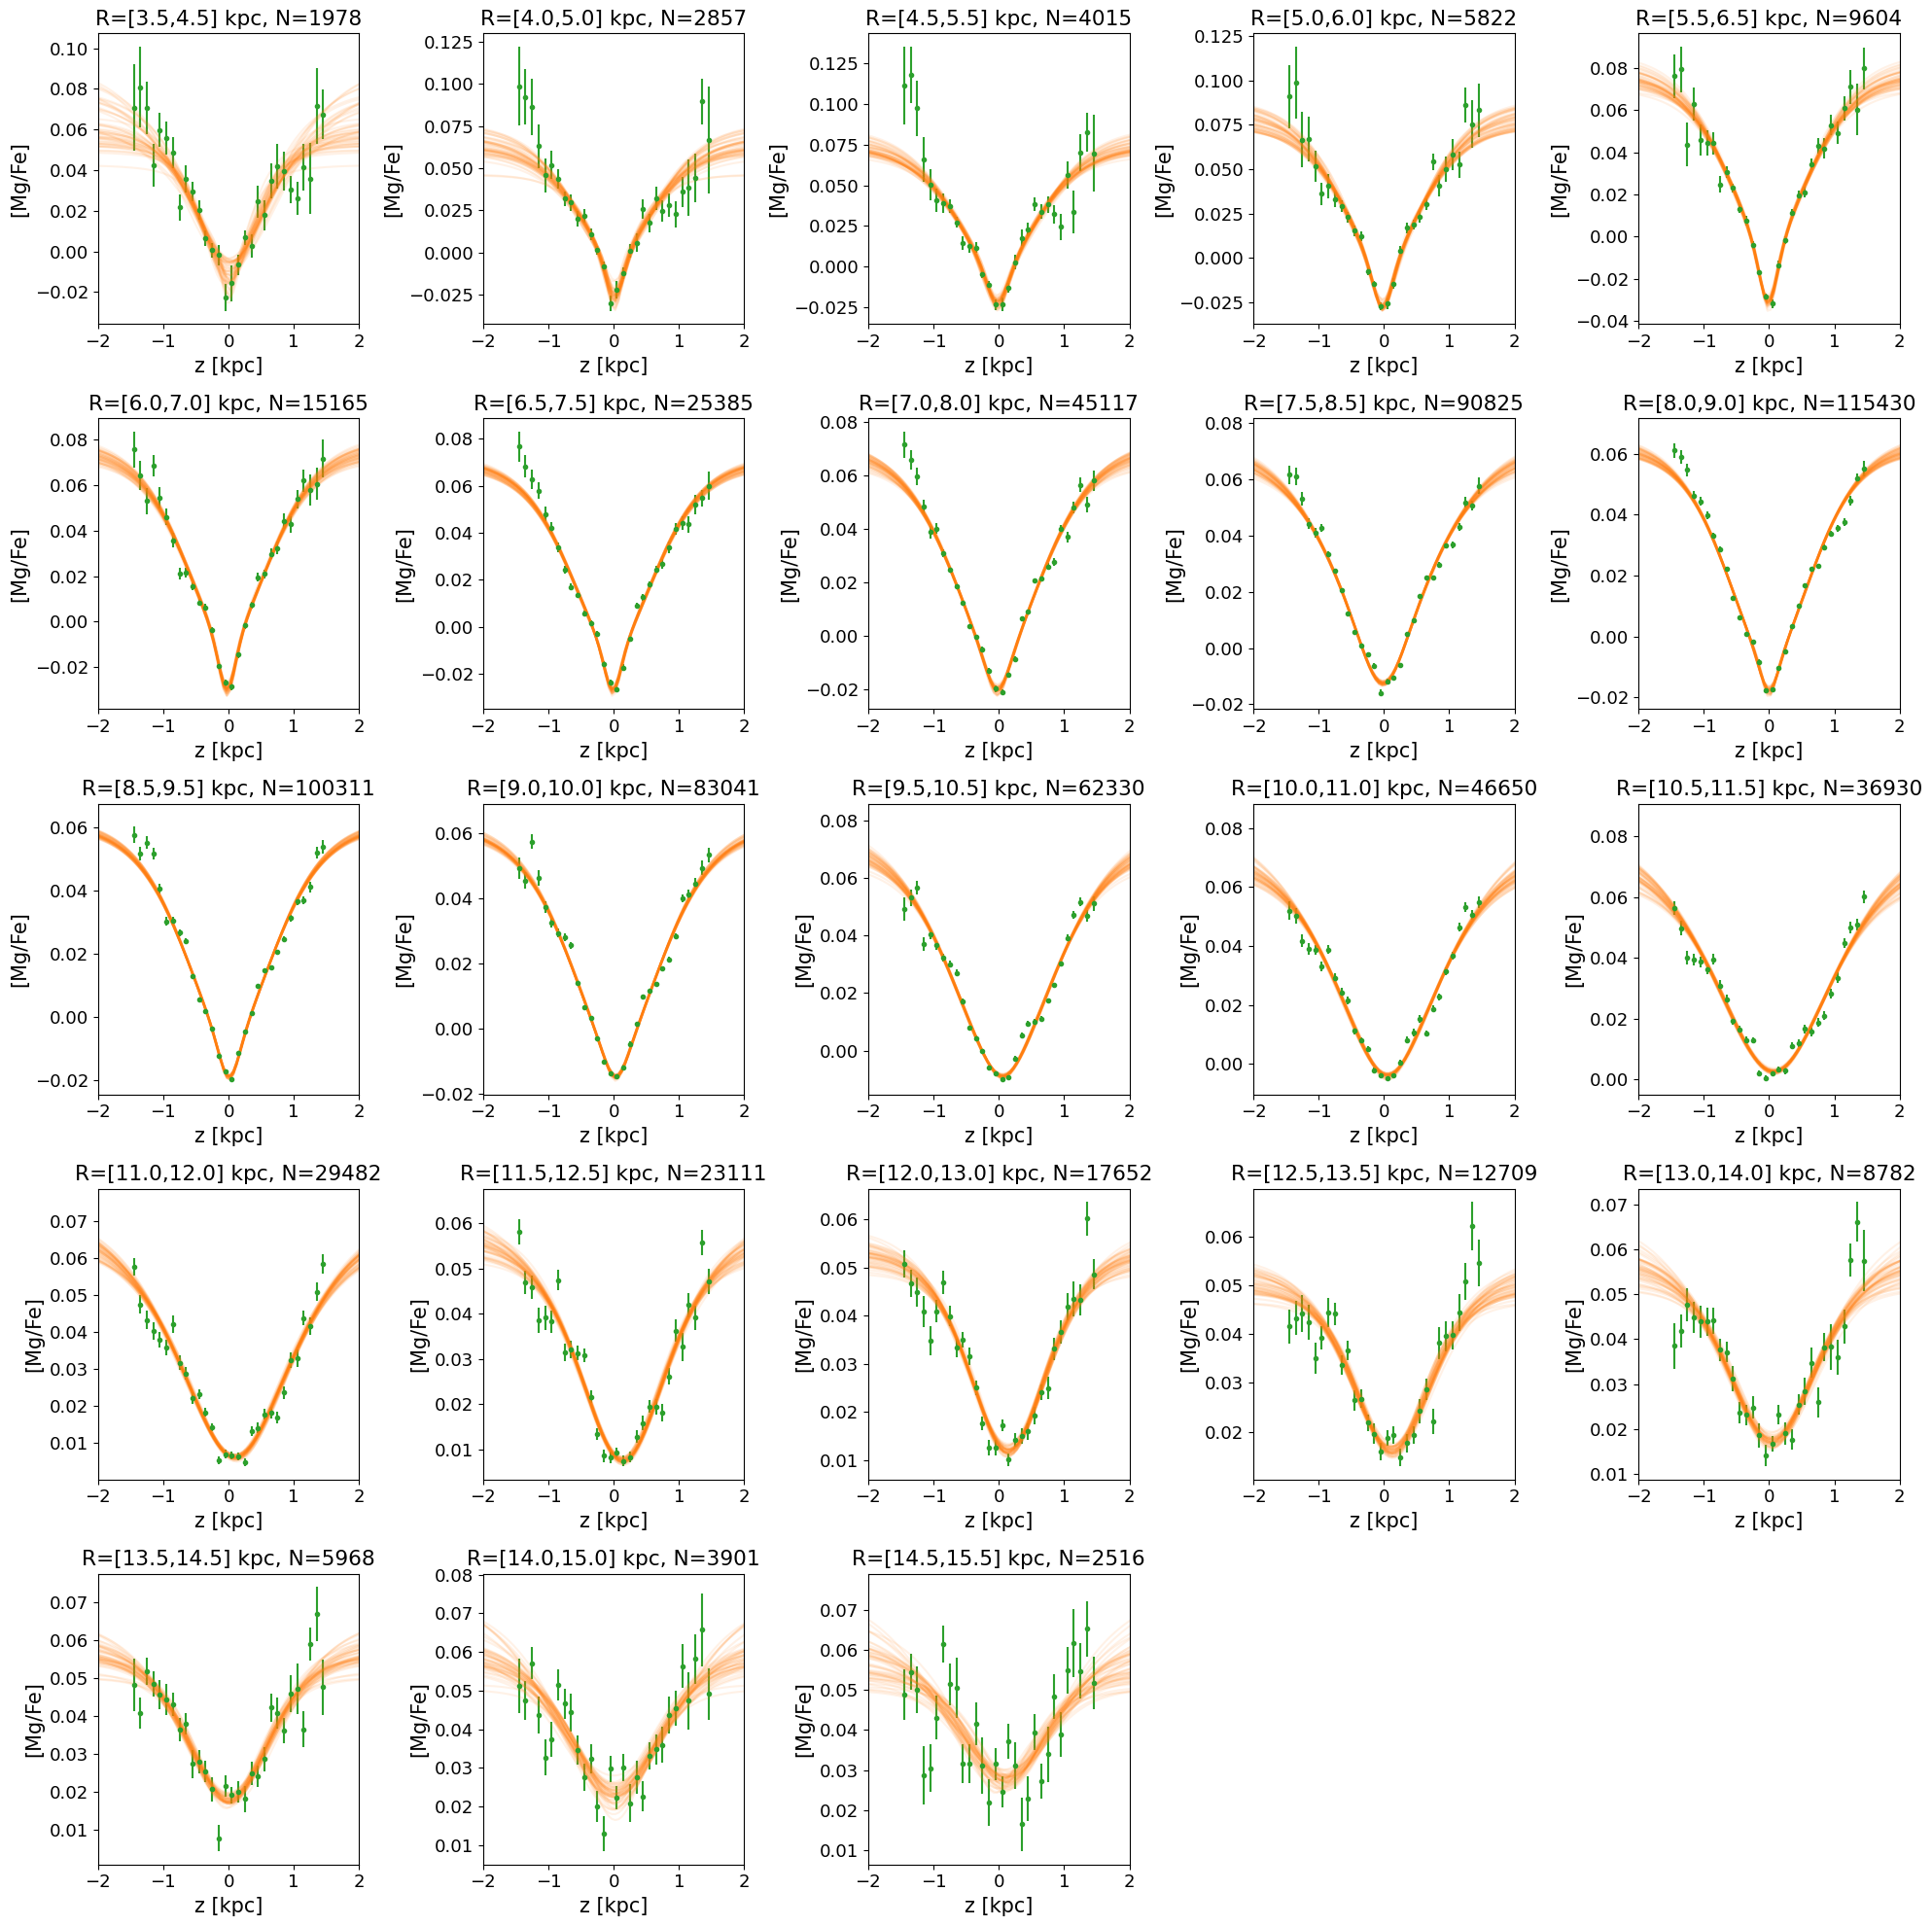

In [238]:
# Diagnostic: model fit + binned data for every radial bin (sanity check)
z_grid = np.linspace(-5, 5, 200)
n_cols = 5
n_rows = int(np.ceil(len(per_R_flare) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), squeeze=False)

for idx, (i_R, cell) in enumerate(per_R_flare.items()):
    r, c = divmod(idx, n_cols)
    ax = axes[r, c]
    s = cell["samples"]

    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                color="C2", linestyle="", marker=".")

    for i in range(min(50, len(s["A1"]))):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        y_pred = mixture_of_sech2(z_grid, cell_sample["A1"], cell_sample["A2"],
                                  cell_sample["h1"], cell_sample["h2"],
                                  cell_sample["z0"]) + cell_sample["offset"]
        ax.plot(z_grid, y_pred, color="C1", alpha=0.1)

    ax.set_xlabel("z [kpc]")
    ax.set_ylabel("[Mg/Fe]")
    ax.set_title(f"R=[{cell['Rlo']:.1f},{cell['Rhi']:.1f}] kpc, N={cell['n_stars']}")
    ax.set_xlim(-2, 2)

for idx in range(len(per_R_flare), n_rows * n_cols):
    r, c = divmod(idx, n_cols)
    axes[r, c].axis("off")

plt.tight_layout()
plt.show()

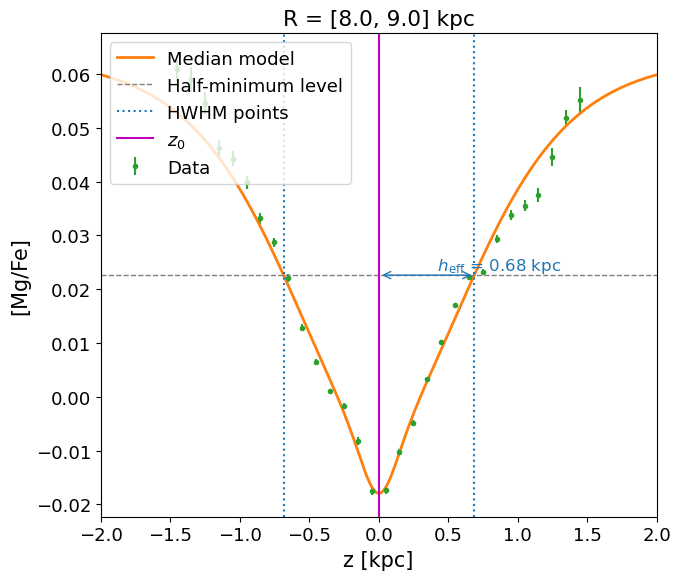

In [312]:
from scipy.optimize import brentq

# find the R=8-9 kpc bin
R_target = (8.0, 9.0)
cell = next(c for c in per_R_flare.values()
            if np.isclose(c["Rlo"], R_target[0]) and np.isclose(c["Rhi"], R_target[1]))

s = cell["samples"]
med = {k: np.median(v) for k, v in s.items()}
med["h2"] = med["h1"] + med["d_h2"]

z_grid = np.linspace(-2, 2, 500)
y_pred = mixture_of_sech2(z_grid, med["A1"], med["A2"], med["h1"], med["h2"], med["z0"]) + med["offset"]

i_min = np.argmin(y_pred)
z_min = z_grid[i_min]
y_min = y_pred[i_min]
y_asym = med["offset"]
half_level = y_min + 0.5 * (y_asym - y_min)

def f(z):
    return mixture_of_sech2(z, med["A1"], med["A2"], med["h1"], med["h2"], med["z0"]) + med["offset"] - half_level

z_left = brentq(f, z_grid[0], z_min)
z_right = brentq(f, z_min, z_grid[-1])
h_eff = z_right - z_min

fig, ax = plt.subplots(figsize=(7, 6))
ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
            color="C2", marker=".", linestyle="", label="Data")
ax.plot(z_grid, y_pred, color="C1", lw=2, label="Median model")

ax.axhline(half_level, color="gray", ls="--", lw=1, label="Half-minimum level")
ax.axvline(z_left, color="C0", ls=":", lw=1.5)
ax.axvline(z_right, color="C0", ls=":", lw=1.5, label="HWHM points")
ax.axvline(med["z0"], color="m", ls="-", lw=1.5, label="$z_0$")
ax.annotate("", xy=(z_right, half_level), xytext=(z_min, half_level),
            arrowprops=dict(arrowstyle="<->", color="C0"))
ax.text((z_min + z_right) / 2, half_level, f"  $h_\\mathrm{{eff}}$ = {h_eff:.2f} kpc",
        va="bottom", ha="left", color="C0", fontsize=12)

ax.set_xlabel("z [kpc]")
ax.set_ylabel("[Mg/Fe]")
ax.set_title(f"R = [{cell['Rlo']:.1f}, {cell['Rhi']:.1f}] kpc")
ax.set_xlim(-2, 2)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:13: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:14: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2802478694.py:24: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


  done 70/330
  done 130/330
  done 140/330
  done 150/330
  done 160/330
  done 170/330
  done 180/330
  done 190/330
  done 200/330
  done 210/330
  done 220/330
  done 230/330
  done 240/330
  done 250/330
  done 260/330
  done 270/330
  done 280/330
  done 290/330
  done 300/330
fits complete: 206 / 330
saved to sech2_mcmc_results_unified.pkl


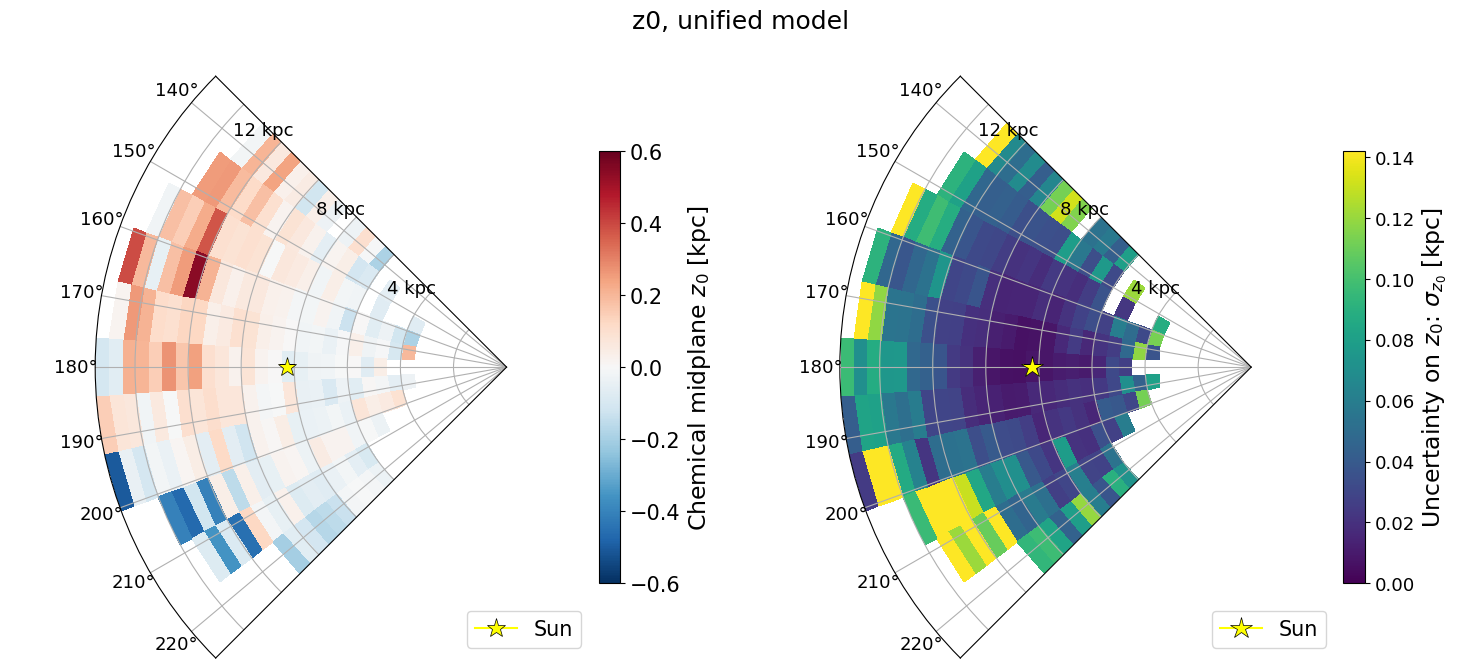

In [241]:
RESULTS_PATH_UNIFIED = "sech2_mcmc_results_unified.pkl"
FORCE_RERUN_UNIFIED = False

if os.path.exists(RESULTS_PATH_UNIFIED) and not FORCE_RERUN_UNIFIED:
    with open(RESULTS_PATH_UNIFIED, "rb") as f:
        saved = pickle.load(f)
    z0_med_u   = saved["z0_med"]
    z0_std_u   = saved["z0_std"]
    n_stars_u  = saved["n_stars"]
    n_bins_u   = saved["n_bins"]
    ok_grid_u  = saved["ok_grid"]
    per_cell_u = saved["per_cell"]
    print(f"loaded results from {RESULTS_PATH_UNIFIED}  "
          f"({int(ok_grid_u.sum())}/{ok_grid_u.size} cells)")
else:
    n_R   = len(R_edges) - 1
    n_seg = len(SEG_PLOT_heat)
    z0_med_u   = np.full((n_R, n_seg), np.nan)
    z0_std_u   = np.full((n_R, n_seg), np.nan)
    n_stars_u  = np.zeros((n_R, n_seg), dtype=int)
    n_bins_u   = np.zeros((n_R, n_seg), dtype=int)
    ok_grid_u  = np.zeros((n_R, n_seg), dtype=bool)
    per_cell_u = {}

    key   = jr.PRNGKey(0)
    pairs = list(product(range(n_R), range(n_seg)))

    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin = float(R_edges[i_R]); Rmax = float(R_edges[i_R + 1])
        seg_id = SEG_PLOT_heat[j_seg]
        z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment(
            R_star, Z_star, mgfe_star, mgfe_err_star,
            seg_mask=segm[seg_id], Rmin=Rmin, Rmax=Rmax,
        )
        n_stars_u[i_R, j_seg] = ns_k
        if not ok_k:
            continue
        n_bins_u[i_R, j_seg] = len(z_binc_k)
        try:
            key, sub = jr.split(key)
            sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
            samples_k = sampler_k.get_samples()
            z0_med_u[i_R, j_seg] = float(np.median(samples_k["z0"]))
            z0_std_u[i_R, j_seg] = float(np.std(samples_k["z0"]))
            ok_grid_u[i_R, j_seg] = True
            per_cell_u[(i_R, j_seg)] = {
                "z_binc": np.asarray(z_binc_k),
                "mean":   np.asarray(mean_k),
                "err":    np.asarray(err_k),
                "samples": {kk: np.asarray(vv[:1000]) for kk, vv in samples_k.items()},
            }
        except Exception as e:
            print(f"  fit failed: seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
        if k % 10 == 0 or k == len(pairs):
            print(f"  done {k}/{len(pairs)}", flush=True)

    print("fits complete:", int(ok_grid_u.sum()), "/", ok_grid_u.size)

    with open(RESULTS_PATH_UNIFIED, "wb") as f:
        pickle.dump({
            "z0_med": z0_med_u, "z0_std": z0_std_u,
            "n_stars": n_stars_u, "n_bins": n_bins_u,
            "ok_grid": ok_grid_u, "per_cell": per_cell_u,
        }, f)
    print(f"saved to {RESULTS_PATH_UNIFIED}")


# ============================================================
# z0 heatmap using the unified-model results
# ============================================================
plot_z0_heatmap(z0_med_u, z0_std_u, "z0, unified model", crowd_bounds, n_seg)

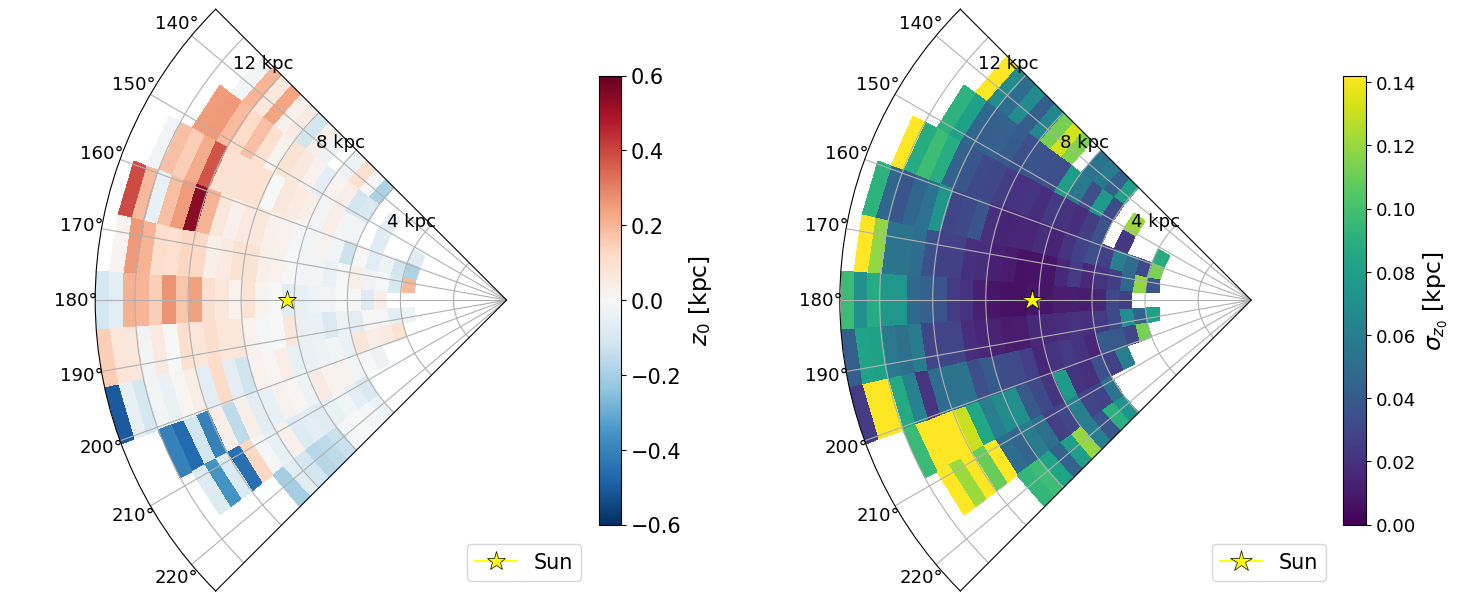

In [291]:
plot_z0_heatmap(z0_med_u, z0_std_u, "")

In [292]:
i_peak = np.unravel_index(np.nanargmax(z0_med_u), z0_med_u.shape)
i_trough = np.unravel_index(np.nanargmin(z0_med_u), z0_med_u.shape)
print("peak z0:", z0_med_u[i_peak], "at R,seg =", i_peak)
print("trough z0:", z0_med_u[i_trough], "at R,seg =", i_trough)

peak z0: 0.5395721037985236 at R,seg = (np.int64(23), np.int64(3))
trough z0: -0.5019824839441444 at R,seg = (np.int64(29), np.int64(7))


In [293]:
R_centers = 0.5 * (R_edges[:-1] + R_edges[1:])

theta_edges_deg = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges_deg)):
    while theta_edges_deg[i] <= theta_edges_deg[i - 1]:
        theta_edges_deg[i] += 2 * np.pi
theta_centers_deg = np.degrees(0.5 * (theta_edges_deg[:-1] + theta_edges_deg[1:]))

R_peak, phi_peak = R_centers[i_peak[0]], theta_centers_deg[i_peak[1]]
R_trough, phi_trough = R_centers[i_trough[0]], theta_centers_deg[i_trough[1]]

print(f"peak:   z0={z0_med_u[i_peak]:.3f} kpc at R={R_peak:.1f} kpc, phi={phi_peak:.0f} deg")
print(f"trough: z0={z0_med_u[i_trough]:.3f} kpc at R={R_trough:.1f} kpc, phi={phi_trough:.0f} deg")

peak:   z0=0.540 kpc at R=12.2 kpc, phi=164 deg
trough: z0=-0.502 kpc at R=15.2 kpc, phi=196 deg


In [294]:
print(f"peak cell:   z0={z0_med_u[i_peak]:.3f} ± {z0_std_u[i_peak]:.3f} kpc")
print(f"trough cell: z0={z0_med_u[i_trough]:.3f} ± {z0_std_u[i_trough]:.3f} kpc")

peak cell:   z0=0.540 ± 0.074 kpc
trough cell: z0=-0.502 ± 0.025 kpc


theta=160 deg falls in segment 4 (index 3)


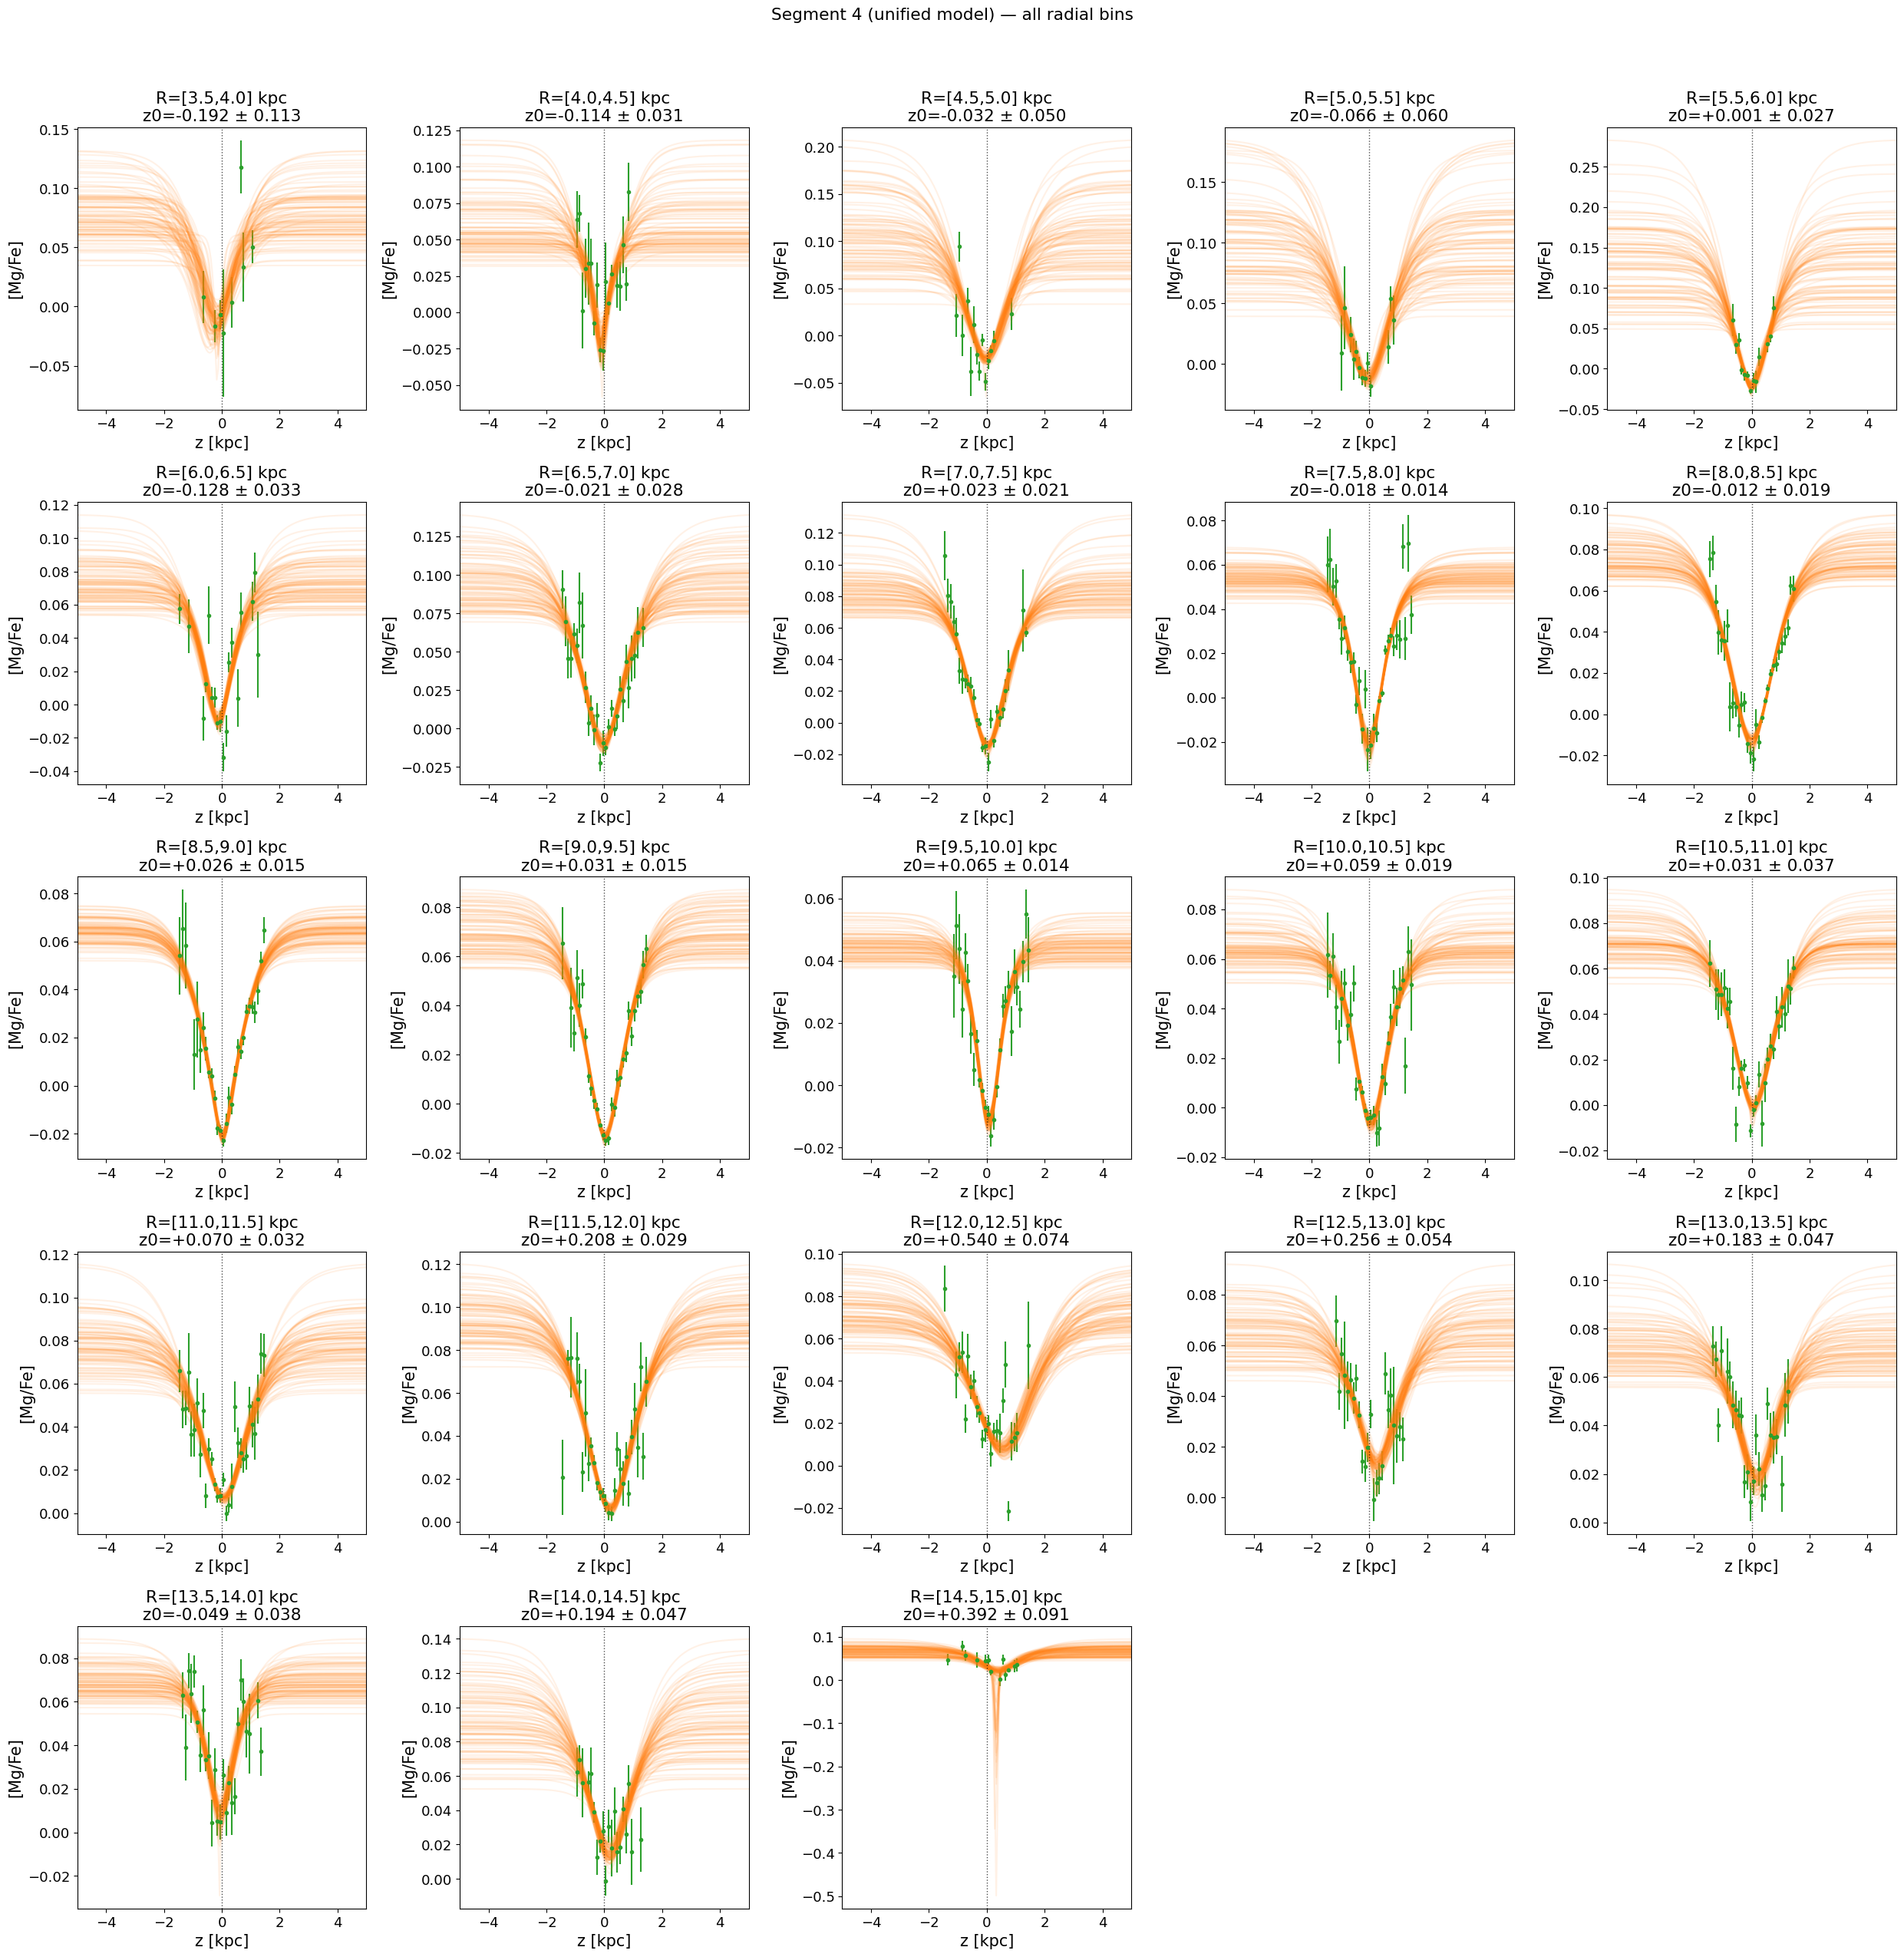

In [246]:
from src.coords import between_ccw

theta_focus = np.radians(160)   # change this to pick a different azimuth

# find which segment contains theta_focus
j_seg_focus = None
for idx, seg_id in enumerate(SEG_PLOT_heat):
    a, b = crowd_bounds[idx], crowd_bounds[idx + 1]
    if between_ccw(np.array([theta_focus]), a, b)[0]:
        j_seg_focus = idx
        seg_id_focus = seg_id
        break

print(f"theta={np.degrees(theta_focus):.0f} deg falls in segment {seg_id_focus} (index {j_seg_focus})")

cells_in_seg = [(i_R, j_seg) for (i_R, j_seg) in per_cell_u.keys() if j_seg == j_seg_focus]
cells_in_seg.sort(key=lambda x: x[0])  # order by radius
n_cells = len(cells_in_seg)

n_cols = 5
n_rows = int(np.ceil(n_cells / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), squeeze=False)
z_grid = np.linspace(-5, 5, 200)

for idx, (i_R, j_seg) in enumerate(cells_in_seg):
    r, c = divmod(idx, n_cols)
    ax = axes[r, c]
    cell = per_cell_u[(i_R, j_seg)]
    s = cell["samples"]

    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                color="C2", linestyle="", marker=".", label="binned mean")

    for i in range(min(100, len(s["A1"]))):
        cell_sample = {k: v[i] for k, v in s.items()}
        cell_sample["h2"] = cell_sample["h1"] + cell_sample["d_h2"]
        y_pred = mixture_of_sech2(z_grid, cell_sample["A1"], cell_sample["A2"],
                                  cell_sample["h1"], cell_sample["h2"],
                                  cell_sample["z0"]) + cell_sample["offset"]
        ax.plot(z_grid, y_pred, color="C1", alpha=0.1)

    ax.axvline(0, color="k", linestyle=":", linewidth=1, alpha=0.7)

    ax.set_xlabel("z [kpc]")
    ax.set_ylabel("[Mg/Fe]")
    ax.set_title(f"R=[{R_edges[i_R]:.1f},{R_edges[i_R+1]:.1f}] kpc\n"
                 f"z0={z0_med_u[i_R,j_seg]:+.3f} \u00b1 {z0_std_u[i_R,j_seg]:.3f}")
    ax.set_xlim(-5, 5)

for idx in range(n_cells, n_rows * n_cols):
    r, c = divmod(idx, n_cols)
    axes[r, c].axis("off")

plt.suptitle(f"Segment {seg_id_focus} (unified model) \u2014 all radial bins", y=1.02)
plt.tight_layout()
plt.show()

## Parameter comparison to Poggio

In [ ]:
# ============================================================
# WARP PARAMETER COMPARISON TO POGGIO (ELOISA'S YOUNG GIANT MODEL)
#
# Goal: fit Poggio's m=1 twisted-line-of-nodes warp model to our own
# chemical midplane z0(R, phi) measurements via NumPyro/MCMC, and
# compare the resulting warp parameters (amplitude, twist rate,
# line-of-nodes orientation) to her young-giant best-fit values --
# both for the full sample and split by age bin.
# ============================================================

import numpy as np
import jax
import jax.numpy as jnp
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
import matplotlib.pyplot as plt

In [258]:
# ------------------------------------------------------------
# STEP 1 -- Poggio's young-giant warp model, in NumPyro
#
# Z_w(R, phi) = h_w(R) * sin(phi - phi_LON(R))
#   h_w(R)     = h_w0 * (R - R_w)^alpha_w      for R > R_w, else 0
#   phi_LON(R) = phi_LON0                       for R <= R_t
#              = phi_LON0 + beta_w*(R - R_t)    for R > R_t
#
# phi must be in Poggio's convention: phi=0 toward the anti-centre,
# increasing in the direction of Galactic rotation (see Step 4).
# ------------------------------------------------------------

POGGIO_YOUNG_GIANT = {
    "R_w": 5.5, "h_w0": 0.012, "alpha_w": 1.9,
    "phi_LON0": 0.1, "R_t": 12.1, "beta_w": 9.9,
}

def warp_model(R, phi_deg, z0_obs=None, z0_err=None):
    """Full 6-parameter model. Used for the unified (all-age) fit,
    which has enough points to constrain R_w and R_t."""
    R_w = numpyro.sample("R_w", dist.Uniform(2.0, 9.0))
    h_w0 = numpyro.sample("h_w0", dist.HalfNormal(0.05))
    alpha_w = numpyro.sample("alpha_w", dist.Uniform(0.5, 3.0))
    phi_LON0 = numpyro.sample("phi_LON0", dist.Normal(0.0, 10.0))
    R_t = numpyro.sample("R_t", dist.Uniform(9.0, 15.0))
    beta_w = numpyro.sample("beta_w", dist.Normal(0.0, 15.0))

    dR = jnp.clip(R - R_w, a_min=0.0)  # avoid NaN grad on negative^fractional power
    h_w = jnp.where(R > R_w, h_w0 * jnp.power(dR, alpha_w), 0.0)
    phi_LON = jnp.where(R <= R_t, phi_LON0, phi_LON0 + beta_w * (R - R_t))
    z_pred = h_w * jnp.sin(jnp.deg2rad(phi_deg) - jnp.deg2rad(phi_LON))

    numpyro.deterministic("z_pred", z_pred)
    numpyro.sample("obs", dist.Normal(z_pred, z0_err), obs=z0_obs)


def warp_model_reduced(R, phi_deg, z0_obs=None, z0_err=None):
    """R_w/R_t fixed to Poggio's values; only amplitude/phase float.
    Used for the sparser age-bin fits (12-184 points), which can't
    reliably constrain all 6 parameters on their own."""
    R_w = POGGIO_YOUNG_GIANT["R_w"]
    R_t = POGGIO_YOUNG_GIANT["R_t"]
    h_w0 = numpyro.sample("h_w0", dist.HalfNormal(0.05))
    alpha_w = numpyro.sample("alpha_w", dist.Uniform(0.5, 4.0))
    phi_LON0 = numpyro.sample("phi_LON0", dist.Normal(0.0, 10.0))
    beta_w = numpyro.sample("beta_w", dist.Normal(0.0, 15.0))

    dR = jnp.clip(R - R_w, a_min=0.0)
    h_w = jnp.where(R > R_w, h_w0 * jnp.power(dR, alpha_w), 0.0)
    phi_LON = jnp.where(R <= R_t, phi_LON0, phi_LON0 + beta_w * (R - R_t))
    z_pred = h_w * jnp.sin(jnp.deg2rad(phi_deg) - jnp.deg2rad(phi_LON))

    numpyro.deterministic("z_pred", z_pred)
    numpyro.sample("obs", dist.Normal(z_pred, z0_err), obs=z0_obs)


def warp_model_straight_LON(R, phi_deg, z0_obs=None, z0_err=None):
    """No twist at all -- phi_LON constant with radius. Cross-check
    model: if phi_LON0 still disagrees with Poggio here, the
    disagreement isn't an artifact of the twisted-LON functional form."""
    R_w = POGGIO_YOUNG_GIANT["R_w"]
    h_w0 = numpyro.sample("h_w0", dist.HalfNormal(0.05))
    alpha_w = numpyro.sample("alpha_w", dist.Uniform(0.5, 4.0))
    phi_LON0 = numpyro.sample("phi_LON0", dist.Normal(0.0, 10.0))

    dR = jnp.clip(R - R_w, a_min=0.0)
    h_w = jnp.where(R > R_w, h_w0 * jnp.power(dR, alpha_w), 0.0)
    z_pred = h_w * jnp.sin(jnp.deg2rad(phi_deg) - jnp.deg2rad(phi_LON0))

    numpyro.deterministic("z_pred", z_pred)
    numpyro.sample("obs", dist.Normal(z_pred, z0_err), obs=z0_obs)

In [ ]:
# ------------------------------------------------------------
# STEP 2 -- fit runner + divergence diagnostics
#
# target_accept_prob=0.95 and max_tree_depth=12 help NUTS handle the
# sharp jnp.where thresholds in the model geometry (needed after the
# original defaults produced 500-5000+ divergences per bin).
# ------------------------------------------------------------

def run_warp_fit(model_fn, R, phi_deg, z0, z0_err, seed=0,
                  num_warmup=1500, num_samples=2000, num_chains=4):
    rng_key = jax.random.PRNGKey(seed)
    kernel = NUTS(model_fn, target_accept_prob=0.95, max_tree_depth=12)
    mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples,
                num_chains=num_chains)
    mcmc.run(rng_key, R=jnp.asarray(R), phi_deg=jnp.asarray(phi_deg),
              z0_obs=jnp.asarray(z0), z0_err=jnp.asarray(z0_err))
    mcmc.print_summary()
    return mcmc


def divergence_report(label, mcmc_obj, n_points):
    n_div = int(mcmc_obj.get_extra_fields()["diverging"].sum())
    n_total = len(mcmc_obj.get_extra_fields()["diverging"])
    pct = 100 * n_div / n_total
    print(f"{label}: {n_points} data points, {n_div}/{n_total} divergences ({pct:.1f}%)")

In [280]:
# ------------------------------------------------------------
# STEP 3 -- build (R, phi, z0, z0_err) arrays from the z0 grids
#
# Uses R_edges, crowd_bounds, and the z0_med/z0_std grids already
# computed earlier in the notebook (unified + young/mid/old).
#
# R cut (9-14.5 kpc) restricts the fit to radii where a warp is
# physically expected (Poggio's own fit only considers R >~ R_sun);
# including inner-disk cells where h_w should be ~0 was part of what
# was driving the original divergences.
# ------------------------------------------------------------

R_centers = 0.5 * (R_edges[:-1] + R_edges[1:])

theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi

phi_centers_deg_emma = np.degrees(0.5 * (theta_edges[:-1] + theta_edges[1:]))

# convert Emma's phi (astropy Galactocentric, Sun at phi=180) to Poggio's
# convention (phi=0 toward anti-centre, increasing with rotation)
phi_centers_deg = 180.0 - phi_centers_deg_emma
phi_centers_deg = (phi_centers_deg + 180) % 360 - 180  # wrap to (-180, 180]

R_grid, Phi_grid = np.meshgrid(R_centers, phi_centers_deg, indexing="ij")


def extract_fit_arrays(z0_med_bin, z0_std_bin, ok_grid_bin=None, R_min=8.277, R_max=14.5):
    mask = (np.isfinite(z0_med_bin) & np.isfinite(z0_std_bin) & (z0_std_bin > 0)
            & (R_grid >= R_min) & (R_grid <= R_max))
    if ok_grid_bin is not None:
        mask &= ok_grid_bin
    return R_grid[mask], Phi_grid[mask], z0_med_bin[mask], z0_std_bin[mask]

In [281]:
# ------------------------------------------------------------
# STEP 4 -- coordinate sanity check
#
# Confirms the phi conversion's rotation-direction assumption: vphi
# should be positive (prograde) given Emma's vphi sign convention.
# ------------------------------------------------------------

from src.coords import build_galactocentric_phase_space

phase, _ = build_galactocentric_phase_space(t_star)
print("median vphi:", np.median(phase["vphi"]), "(expect ~ +200-250 km/s, prograde)")

median vphi: 229.0856533135488 (expect ~ +200-250 km/s, prograde)


In [282]:
# ------------------------------------------------------------
# STEP 5 -- unified (all-age) fit, full 6-parameter model
# ------------------------------------------------------------

R_u, phi_u, z0_u, z0err_u = extract_fit_arrays(z0_med_u, z0_std_u, ok_grid_u)
print(f"unified: {len(z0_u)} cells going into the fit")

mcmc_unified = run_warp_fit(warp_model, R_u, phi_u, z0_u, z0err_u)
samples_unified = mcmc_unified.get_samples()
divergence_report("unified", mcmc_unified, len(z0_u))

unified: 117 cells going into the fit


/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2532437872.py:104: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples,
sample: 100%|█| 3500/3500 [00:07<00:00, 469.42it/s, 127 steps of size 2.64e-02. 
sample: 100%|█| 3500/3500 [00:06<00:00, 545.52it/s, 127 steps of size 2.73e-02. 
sample: 100%|█| 3500/3500 [00:05<00:00, 638.08it/s, 63 steps of size 3.67e-02. a
sample: 100%|█| 3500/3500 [00:05<00:00, 643.00it/s, 127 steps of size 3.97e-02. 


                mean       std    median      5.0%     95.0%     n_eff     r_hat
       R_t     12.31      0.28     12.31     11.88     12.76   2745.59      1.00
       R_w      7.67      0.59      7.78      6.87      8.52   1826.91      1.00
   alpha_w      1.39      0.33      1.34      0.88      1.88   1867.54      1.00
    beta_w     11.65      2.81     11.60      7.11     16.20   3333.78      1.00
      h_w0      0.04      0.02      0.03      0.00      0.06   2453.68      1.00
  phi_LON0    -25.68      2.52    -25.57    -29.80    -21.62   3653.45      1.00

Number of divergences: 0
unified: 117 data points, 0/8000 divergences (0.0%)


In [283]:
# ------------------------------------------------------------
# STEP 6 -- age-bin fits, reduced model (R_w/R_t fixed)
# ------------------------------------------------------------

R_young, phi_young, z0_young, z0err_young = extract_fit_arrays(z0_med_young, z0_std_young)
R_mid,   phi_mid,   z0_mid,   z0err_mid   = extract_fit_arrays(z0_med_mid,   z0_std_mid)
R_old,   phi_old,   z0_old,   z0err_old   = extract_fit_arrays(z0_med_old,   z0_std_old)
print(f"young: {len(z0_young)} cells, mid: {len(z0_mid)} cells, old: {len(z0_old)} cells")

mcmc_young = run_warp_fit(warp_model_reduced, R_young, phi_young, z0_young, z0err_young)
samples_young = mcmc_young.get_samples()
divergence_report("young", mcmc_young, len(z0_young))

mcmc_mid = run_warp_fit(warp_model_reduced, R_mid, phi_mid, z0_mid, z0err_mid)
samples_mid = mcmc_mid.get_samples()
divergence_report("mid", mcmc_mid, len(z0_mid))

mcmc_old = run_warp_fit(warp_model_reduced, R_old, phi_old, z0_old, z0err_old)
samples_old = mcmc_old.get_samples()
divergence_report("old", mcmc_old, len(z0_old))

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2532437872.py:104: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples,


young: 78 cells, mid: 111 cells, old: 17 cells


sample: 100%|█| 3500/3500 [00:03<00:00, 1157.66it/s, 43 steps of size 4.86e-02. 
sample: 100%|█| 3500/3500 [00:02<00:00, 1672.59it/s, 31 steps of size 5.59e-02. 
sample: 100%|█| 3500/3500 [00:02<00:00, 1492.73it/s, 127 steps of size 5.46e-02.
sample: 100%|█| 3500/3500 [00:02<00:00, 1582.91it/s, 87 steps of size 5.45e-02. 



                mean       std    median      5.0%     95.0%     n_eff     r_hat
   alpha_w      3.12      0.50      3.15      2.41      3.95   1836.45      1.00
    beta_w     -4.12      7.41     -3.02    -16.02      7.05   2097.43      1.00
      h_w0      0.00      0.00      0.00      0.00      0.00   1675.81      1.00
  phi_LON0    -23.22      5.04    -22.97    -31.37    -14.94   2801.10      1.00

Number of divergences: 0
young: 78 data points, 0/8000 divergences (0.0%)


sample: 100%|█| 3500/3500 [00:02<00:00, 1228.00it/s, 31 steps of size 6.33e-02. 
sample: 100%|█| 3500/3500 [00:01<00:00, 1774.44it/s, 31 steps of size 7.93e-02. 
sample: 100%|█| 3500/3500 [00:01<00:00, 1770.45it/s, 47 steps of size 8.08e-02. 
sample: 100%|█| 3500/3500 [00:01<00:00, 1751.73it/s, 31 steps of size 7.66e-02. 



                mean       std    median      5.0%     95.0%     n_eff     r_hat
   alpha_w      1.85      0.24      1.85      1.45      2.24   2573.72      1.00
    beta_w     12.29      2.49     12.27      8.13     16.31   2414.50      1.00
      h_w0      0.01      0.00      0.01      0.00      0.01   2384.02      1.00
  phi_LON0    -23.34      3.12    -23.18    -28.50    -18.41   2294.53      1.00

Number of divergences: 0
mid: 111 data points, 0/8000 divergences (0.0%)


sample: 100%|█| 3500/3500 [00:01<00:00, 2237.99it/s, 31 steps of size 9.74e-02. 
sample: 100%|█| 3500/3500 [00:00<00:00, 4074.22it/s, 31 steps of size 9.13e-02. 
sample: 100%|█| 3500/3500 [00:00<00:00, 3657.18it/s, 31 steps of size 1.13e-01. 
sample: 100%|█| 3500/3500 [00:00<00:00, 3839.29it/s, 31 steps of size 9.56e-02. 



                mean       std    median      5.0%     95.0%     n_eff     r_hat
   alpha_w      2.06      0.70      1.99      0.93      3.24   2567.58      1.00
    beta_w      0.18     14.81      0.36    -24.75     23.77   4785.88      1.00
      h_w0      0.03      0.02      0.02      0.00      0.06   2967.60      1.00
  phi_LON0    -14.55      4.45    -14.08    -21.29     -7.29   3525.53      1.00

Number of divergences: 0
old: 17 data points, 0/8000 divergences (0.0%)


In [284]:
# ------------------------------------------------------------
# STEP 7 -- straight-line-of-nodes cross-check (unified sample)
#
# A structurally different model (no twist term at all). If phi_LON0
# still disagrees with Poggio here, the disagreement found under the
# twisted-LON model isn't an artifact of that functional form.
# ------------------------------------------------------------

mcmc_straight = run_warp_fit(warp_model_straight_LON, R_u, phi_u, z0_u, z0err_u)
samples_straight = mcmc_straight.get_samples()
divergence_report("unified (straight LON)", mcmc_straight, len(z0_u))
print("phi_LON0 (straight LON):", samples_straight["phi_LON0"].mean(),
      "+/-", samples_straight["phi_LON0"].std())

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_70568/2532437872.py:104: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples,
sample: 100%|█| 3500/3500 [00:02<00:00, 1671.88it/s, 31 steps of size 9.29e-02. 
sample: 100%|█| 3500/3500 [00:01<00:00, 2472.27it/s, 47 steps of size 7.46e-02. 
sample: 100%|█| 3500/3500 [00:01<00:00, 2315.66it/s, 23 steps of size 8.00e-02. 
sample: 100%|█| 3500/3500 [00:01<00:00, 2597.79it/s, 15 steps of size 1.02e-01. 


                mean       std    median      5.0%     95.0%     n_eff     r_hat
   alpha_w      1.92      0.13      1.92      1.69      2.11   2534.58      1.00
      h_w0      0.01      0.00      0.01      0.00      0.01   2427.49      1.00
  phi_LON0    -20.51      1.94    -20.43    -23.74    -17.42   2896.04      1.00

Number of divergences: 0
unified (straight LON): 117 data points, 0/8000 divergences (0.0%)
phi_LON0 (straight LON): -20.512250594237578 +/- 1.9428917759794295


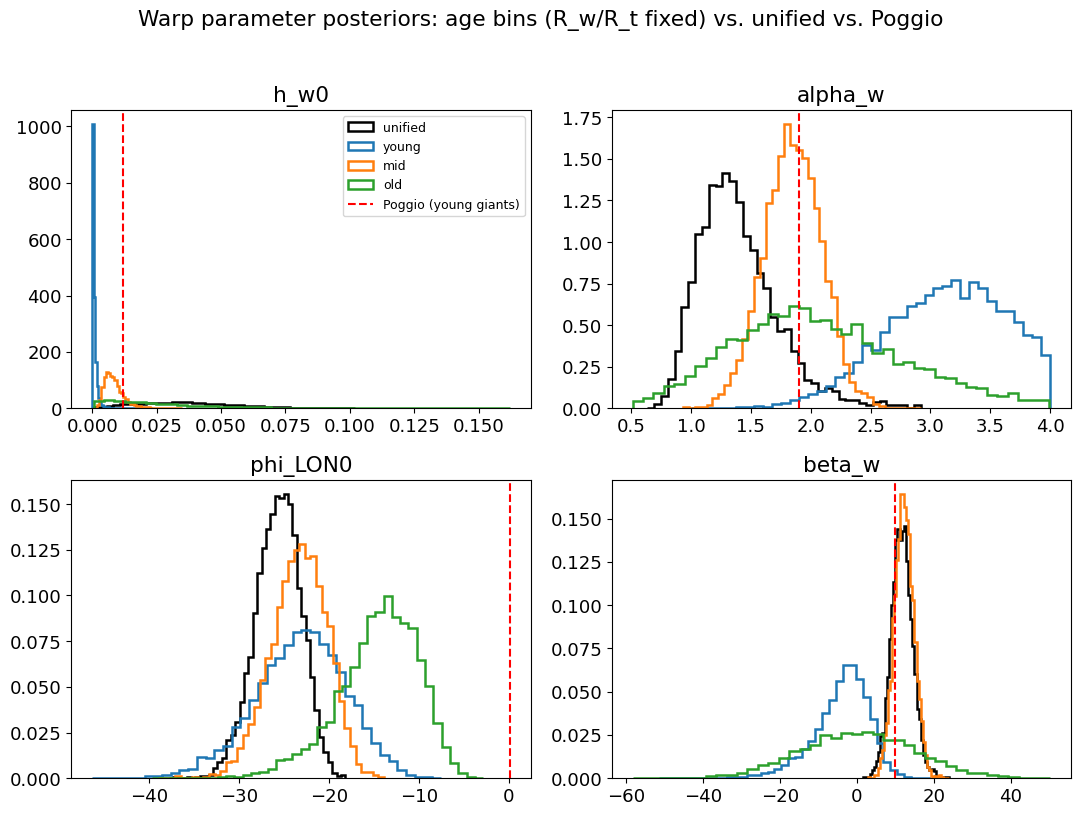

In [285]:
# ------------------------------------------------------------
# STEP 8 -- posterior comparison plot
#
# Only the 4 parameters shared between the full and reduced models
# (h_w0, alpha_w, phi_LON0, beta_w) -- R_w/R_t were only fit for the
# unified sample, not the age bins.
# ------------------------------------------------------------

param_names = ["h_w0", "alpha_w", "phi_LON0", "beta_w"]
bins_to_plot = [
    ("unified", samples_unified, "k"),
    ("young",   samples_young,   "C0"),
    ("mid",     samples_mid,     "C1"),
    ("old",     samples_old,     "C2"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, pname in zip(axes.flat, param_names):
    for label, samples, color in bins_to_plot:
        ax.hist(samples[pname], bins=40, density=True, histtype="step",
                color=color, label=label, linewidth=1.8)
    ax.axvline(POGGIO_YOUNG_GIANT[pname], color="red", linestyle="--",
               linewidth=1.5, label="Poggio (young giants)" if pname == "h_w0" else None)
    ax.set_title(pname)

axes[0, 0].legend(fontsize=9)
plt.suptitle("Warp parameter posteriors: age bins (R_w/R_t fixed) vs. unified vs. Poggio", y=1.02)
plt.tight_layout()
plt.show()

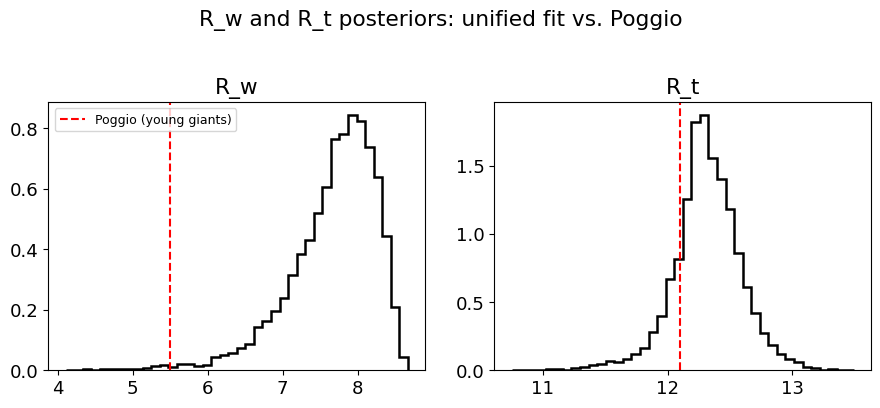

In [286]:
# ------------------------------------------------------------
# STEP 8b -- R_w and R_t posteriors, unified fit only
#
# These weren't fit for the age bins (fixed to Poggio's values in
# warp_model_reduced), so this is just the unified posterior vs.
# her point value -- not a multi-bin comparison like Step 8.
# ------------------------------------------------------------
 
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
 
axes[0].hist(samples_unified["R_w"], bins=40, density=True,
             histtype="step", color="k", linewidth=1.8)
axes[0].axvline(POGGIO_YOUNG_GIANT["R_w"], color="red", linestyle="--",
                linewidth=1.5, label="Poggio (young giants)")
axes[0].set_title("R_w")
axes[0].legend(fontsize=9)
 
axes[1].hist(samples_unified["R_t"], bins=40, density=True,
             histtype="step", color="k", linewidth=1.8)
axes[1].axvline(POGGIO_YOUNG_GIANT["R_t"], color="red", linestyle="--",
                linewidth=1.5)
axes[1].set_title("R_t")
 
plt.suptitle("R_w and R_t posteriors: unified fit vs. Poggio", y=1.02)
plt.tight_layout()
plt.show()

**Warp model parameters** — `Z_w(R,φ) = h_w(R) · sin(φ − φ_LON(R))`

- `R_w` — radius where the warp turns on (flat/zero amplitude inside it). Poggio: 5.5 kpc
- `h_w0`, `alpha_w` — amplitude normalization and growth rate: `h_w(R) = h_w0·(R−R_w)^alpha_w`. Poggio: 0.012, 1.9
- `phi_LON0` — inner-disk line-of-nodes angle (which way the warp's "high side" points). Poggio: ~0.1°
- `R_t` — radius where the line-of-nodes starts twisting. Poggio: 12.1 kpc
- `beta_w` — twist rate of the line-of-nodes beyond R_t (deg/kpc). Poggio: 9.9 deg/kpc

Age bins fix `R_w`/`R_t` to Poggio's values (too few points to constrain all 6 params); only amplitude/phase float.